# Fase 3 – Preparação dos Dados (Data Preparation)

> **CRISP-DM:** construir, a partir dos dados iniciais, o(s) dataset(s) final(ais) que serão usados na modelação. Inclui a seleção de dados (3.1), a limpeza (3.2), a construção de novos atributos e registos (3.3), a integração e agregação de tabelas (3.4) e a formatação para as ferramentas de modelação (3.5). Outputs: *Dataset* e *Dataset Description*.

Nesta fase, ao contrário da Fase 2, os dados são **corrigidos e transformados**. As correções seguem os problemas identificados no Relatório de Qualidade dos Dados (2.4). Os ficheiros originais nunca são alterados: todas as operações são feitas em cópias, e os datasets finais são gravados como ficheiros novos.

**Datasets a produzir (um por objetivo de data mining)**

| Dataset | Objetivo | Unidade (1 linha =) | Variável alvo |
|---|---|---|---|
| D1 | DM1 – Classificação das patologias | episódio-dia com sinais vitais | patologias desse dia (multi-label) |
| D2 | DM2 – Regressão da duração do internamento | episódio-dia com sinais vitais | nº de dias que faltam até à alta |
| D3 | DM3 – Clustering de episódios | episódio | — (sem variável alvo) |

**Pressupostos**

Algumas decisões dependem de respostas do docente que ainda não foram obtidas. Até lá, assumem-se os seguintes pressupostos, que poderão ser revistos:

| # | Pressuposto | Justificação | Onde é usado |
|---|---|---|---|
| P1 | A duração do internamento é o nº de dias distintos com sinais vitais de cada episódio | Indicação do docente | 3.3, D2 |
| P2 | Só os episódio-dia com sinais vitais entram no D1; as patologias registadas em dias sem sinais vitais não são usadas como etiquetas diárias | Sem sinais vitais não há variáveis de entrada para esse dia | 3.1, D1 |
| P3 | Um episódio-dia com sinais vitais e sem patologia registada é tratado como "sem patologia" | Não existe outra forma de representar estes dias; a confirmar com o docente | 3.3, D1 |
| P4 | Os valores dos sinais vitais fora do domínio (999, 99, negativos, 0, etc.) são tratados como valores em falta | Não são medições possíveis (2.4.6) | 3.2 |
| P5 | Os 13 episódios que começam ou terminam nos limites do período dos dados são mantidos, com uma variável que os identifica | Excluí-los reduziria muito o nº de episódios (47); a variável permite avaliar o seu efeito na modelação | 3.1, 3.3 |
| P6 | Na regressão prevê-se, em cada episódio-dia, o nº de dias que faltam até à alta (duração do internamento menos o dia atual), usando apenas os dados desse dia e dos anteriores. As linhas do 1.º dia correspondem à previsão da duração à entrada. Os episódios que terminam no último dia do período não entram no treino da regressão, porque a sua alta é desconhecida | Antecipar a duração (O1) diariamente, aproveitando todos os episódio-dia (cerca de 450 em vez de 47 episódios) e sem dar ao modelo informação do futuro (fuga de informação) | 3.1, 3.3, D2 |
| P7 | As patologias que não aparecem nos dados não são consideradas; o tratamento das patologias raras é decidido na 3.1 | Não é possível aprender uma classe sem exemplos | 3.1 |
| P8 | As variáveis de entrada de cada episódio-dia (D1 e D2) usam apenas dados desse dia e dos dias anteriores do mesmo episódio. No D1 as patologias não são usadas como variáveis de entrada (são o que se pretende prever); no D2 entram as patologias registadas no próprio dia, que são conhecidas nesse momento | Evita usar informação do futuro (fuga de informação); no D1 garante que o modelo deteta as patologias a partir dos sinais vitais, e não por copiar dias anteriores; no D2 aproveita o diagnóstico conhecido, que influencia a duração do internamento | 3.3, D1, D2 |

## 3.1 Seleção dos Dados (Select Data)
> **CRISP-DM:** decidir que dados são usados na análise, com base na relevância para os objetivos de data mining, na qualidade e em restrições técnicas. A seleção abrange atributos (colunas) e registos (linhas). Output: *Rationale for inclusion/exclusion*, com a lista dos dados incluídos e excluídos e as razões dessas decisões.

As decisões desta secção baseiam-se nos resultados da Fase 2. A seleção de registos que depende de códigos, datas ou nomes corrigidos é aplicada depois da limpeza (3.2); aqui fica definida e justificada.

In [1]:
# =============================================================================
# 3.1.1 Bibliotecas, estilo dos gráficos e carregamento dos dados
# Mesmas bibliotecas, paleta de cores e estilo do notebook da Fase 2, para
# que os gráficos das duas fases tenham o mesmo aspeto.
# Os dois ficheiros são lidos tal como foram fornecidos (df_sinais_orig e
# df_patologias_orig). Estas tabelas nunca são alteradas: todas as operações
# da Fase 3 são feitas em cópias.
# =============================================================================
import os
import re
import unicodedata
import difflib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Paleta de cores (igual à da Fase 2)
AZUL, AZUL_CLARO, VERMELHO, LARANJA, CINZA = "#2F5496", "#DCE6F2", "#C00000", "#F4B183", "#555555"

sns.set_theme(style="whitegrid", rc={
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#EEEEEE", "figure.dpi": 100,
})

PASTA_DADOS = "dados/"
FICH_SINAIS = "sinais_vitais_por_hora.csv"
FICH_PATOLOGIAS = "patologias_por_dia.csv"

df_sinais_orig = pd.read_csv(os.path.join(PASTA_DADOS, FICH_SINAIS))
df_patologias_orig = pd.read_csv(os.path.join(PASTA_DADOS, FICH_PATOLOGIAS))

print(f"Sinais vitais: {df_sinais_orig.shape[0]} linhas × {df_sinais_orig.shape[1]} colunas")
print(f"Patologias:    {df_patologias_orig.shape[0]} linhas × {df_patologias_orig.shape[1]} colunas")

Sinais vitais: 9857 linhas × 6 colunas
Patologias:    696 linhas × 3 colunas


In [2]:
# =============================================================================
# 3.1.2 Funções de normalização e listas de referência
# Funções usadas na seleção (3.1) e na limpeza (3.2). Seguem as regras
# definidas e validadas na tarefa 2.4 (Verificação da Qualidade dos Dados):
# - normalizar_codigo:    ' ep018', 'EP 016' -> 'EP018', 'EP016' (2.4.3)
# - corrigir_data:        'AAAA-MM-DD' válida ou 'DD/MM/AAAA' -> data;
#                         datas impossíveis (2024-13-02, 31/02) -> NaT (2.4.4)
# - normalizar_patologia: variantes ('DMH', 'Sepsis', 'ANEMIA'…) -> nome
#                         oficial (2.4.7)
# Também se definem os nomes das colunas dos sinais vitais e a lista oficial
# das 13 patologias.
# =============================================================================
VITAIS = ["sat_o2", "puls_rate", "perfusion"]
OFICIAIS = ["Doença das membranas hialinas", "Icterícia neonatal", "Anemia", "Citomegalovírus",
            "Displasia broncopulmonar", "Persistência do canal arterial", "Refluxo gastroesofágico",
            "Sépsis", "Lesão renal aguda", "Retinopatia da prematuridade",
            "Hemorragia peri-intraventricular", "Enterocolite necrosante",
            "Doença metabólica óssea da prematuridade"]

def normalizar_codigo(codigo):
    """Código no formato EPnnn, ou None se não for reconhecível."""
    limpo = re.sub(r"[^A-Z0-9]", "", str(codigo).upper())
    m = re.fullmatch(r"(?:EP|E|P)?(\d{1,3})", limpo)
    return f"EP{int(m.group(1)):03d}" if m else None

def corrigir_data(texto):
    """Data a partir de 'AAAA-MM-DD' ou 'DD/MM/AAAA'; NaT se não for recuperável."""
    s = str(texto).strip()
    m = re.fullmatch(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    if m:
        d, mes, a = m.groups()
        s = f"{a}-{int(mes):02d}-{int(d):02d}"
    return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")

def simples(texto):
    """Minúsculas, sem acentos e com espaços simples (só para comparar)."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return " ".join(t.lower().split())

OFICIAIS_SIMPLES = {simples(o): o for o in OFICIAIS}
ABREVIATURAS = {"dmh": "doenca das membranas hialinas", "cmv": "citomegalovirus",
                "pca": "persistencia do canal arterial", "rge": "refluxo gastroesofagico",
                "dbp": "displasia broncopulmonar", "rop": "retinopatia da prematuridade",
                "lra": "lesao renal aguda", "ecn": "enterocolite necrosante",
                "nec": "enterocolite necrosante", "hpiv": "hemorragia peri-intraventricular"}

def normalizar_patologia(valor):
    """Nome oficial da patologia, ou None se estiver em falta ou não for reconhecível."""
    if pd.isna(valor) or not str(valor).strip():
        return None
    s = simples(valor)
    if s in OFICIAIS_SIMPLES:                                    # espaços, maiúsculas, acentos
        return OFICIAIS_SIMPLES[s]
    abrev = ABREVIATURAS.get(s.replace(".", ""))
    if abrev in OFICIAIS_SIMPLES:                                # abreviaturas
        return OFICIAIS_SIMPLES[abrev]
    comecam = [o for k, o in OFICIAIS_SIMPLES.items() if k.startswith(s + " ")]
    if len(comecam) == 1:                                        # nome incompleto
        return comecam[0]
    parecido = difflib.get_close_matches(s, OFICIAIS_SIMPLES.keys(), n=1, cutoff=0.8)
    return OFICIAIS_SIMPLES[parecido[0]] if parecido else None   # gralha

# Verificação rápida das funções
print([normalizar_codigo(c) for c in [" ep018", "EP 016", "EP001"]])
print([str(corrigir_data(d))[:10] for d in ["2024-02-10", "10/02/2024", "2024-13-02", "2024-02-31"]])
print([normalizar_patologia(p) for p in ["DMH", "Sepsis", "ANEMIA ", "icterícia", "Doenca das membranas hialinas"]])

['EP018', 'EP016', 'EP001']
['2024-02-10', '2024-02-10', 'NaT', 'NaT']
['Doença das membranas hialinas', 'Sépsis', 'Anemia', 'Icterícia neonatal', 'Doença das membranas hialinas']


,episódio-dia (todos),episódio-dia com sinais vitais,episódios (todos),episódios com sinais vitais,decisão
patologia,,,,,
Doença das membranas hialinas,282,236,28,26,modelar
Icterícia neonatal,161,117,21,20,modelar
Anemia,56,43,7,6,modelar
Citomegalovírus,49,32,7,6,modelar
Persistência do canal arterial,31,30,3,3,modelar
Displasia broncopulmonar,38,37,2,2,modelar
Sépsis,18,12,3,2,modelar
Refluxo gastroesofágico,27,23,2,1,manter no dataset
Lesão renal aguda,3,2,1,1,manter no dataset


modelar (7): ['Doença das membranas hialinas', 'Icterícia neonatal', 'Anemia', 'Citomegalovírus', 'Persistência do canal arterial', 'Displasia broncopulmonar', 'Sépsis']
manter no dataset (2): ['Refluxo gastroesofágico', 'Lesão renal aguda']
excluir (4): ['Retinopatia da prematuridade', 'Hemorragia peri-intraventricular', 'Enterocolite necrosante', 'Doença metabólica óssea da prematuridade']


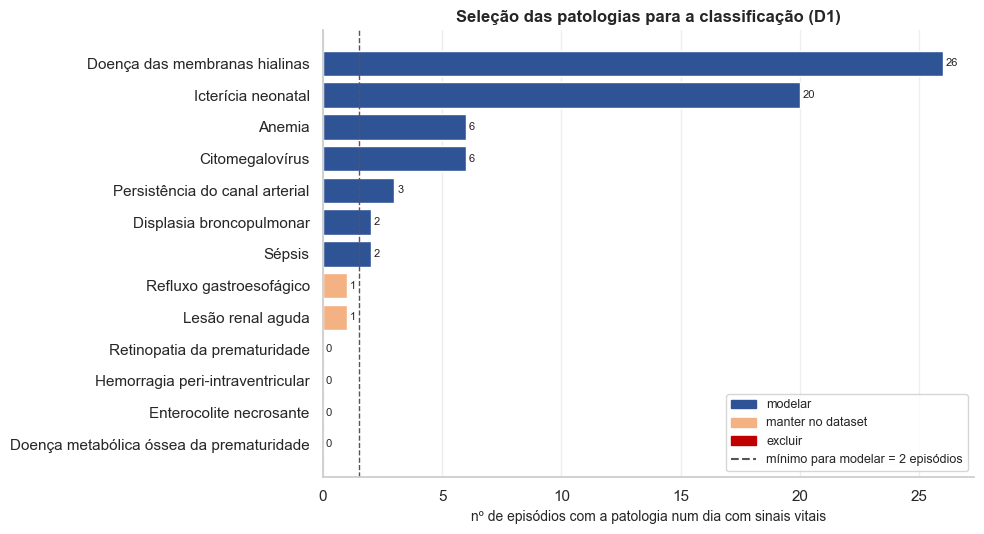

In [3]:
# =============================================================================
# 3.1.3 Seleção das patologias (P7)
# Uma patologia só pode ser modelada no D1 (classificação) se houver
# exemplos suficientes para o modelo aprender e ser avaliado. Como treino e
# teste vão ser separados por episódio (os dias do mesmo bebé são muito
# parecidos), o critério é o nº de EPISÓDIOS com a patologia num dia com
# sinais vitais (P2), e não o nº de registos.
# Critério (três níveis):
# - modelar: aparece em pelo menos MIN_EPISODIOS episódios com sinais vitais
#   (mínimo para poder estar no treino e no teste ao mesmo tempo)
# - manter no dataset: aparece em 1 episódio com sinais vitais; fica como
#   coluna do D1 (não se perde informação), mas não é modelada
# - excluir: não aparece em nenhum dia com sinais vitais
# Contagem feita numa vista temporária com códigos, datas e nomes
# normalizados (funções da 3.1.2) e sem linhas repetidas.
# =============================================================================
MIN_EPISODIOS = 2

# Episódio-dia com sinais vitais
dias_sinais = set(zip(df_sinais_orig["episodio"].map(normalizar_codigo),
                      df_sinais_orig["data"].map(corrigir_data)))

vista_p = pd.DataFrame({"episodio": df_patologias_orig["episodio"].map(normalizar_codigo),
                        "data": df_patologias_orig["data"].map(corrigir_data),
                        "patologia": df_patologias_orig["patologia"].map(normalizar_patologia)})
vista_p = vista_p.dropna().drop_duplicates()
vista_p["tem sinais vitais"] = [(e, d) in dias_sinais for e, d in zip(vista_p["episodio"], vista_p["data"])]
com_sv = vista_p[vista_p["tem sinais vitais"]]

sel_pat = pd.DataFrame({
    "episódio-dia (todos)": vista_p.groupby("patologia").size(),
    "episódio-dia com sinais vitais": com_sv.groupby("patologia").size(),
    "episódios (todos)": vista_p.groupby("patologia")["episodio"].nunique(),
    "episódios com sinais vitais": com_sv.groupby("patologia")["episodio"].nunique(),
}).reindex(OFICIAIS).fillna(0).astype(int)
n_ep = sel_pat["episódios com sinais vitais"]
sel_pat["decisão"] = np.select([n_ep >= MIN_EPISODIOS, n_ep >= 1],
                               ["modelar", "manter no dataset"], "excluir")
sel_pat = sel_pat.sort_values(["episódios com sinais vitais", "episódio-dia com sinais vitais"], ascending=False)
display(sel_pat)

PATOLOGIAS_D1 = sel_pat.index[sel_pat["decisão"] != "excluir"].tolist()        # colunas do D1
PATOLOGIAS_MODELO = sel_pat.index[sel_pat["decisão"] == "modelar"].tolist()    # modeladas na Fase 4
for decisao in ["modelar", "manter no dataset", "excluir"]:
    lista = sel_pat.index[sel_pat["decisão"] == decisao].tolist()
    print(f"{decisao} ({len(lista)}): {lista}")

# --- Gráfico: nº de episódios com cada patologia (em dias com sinais vitais)
fig, ax = plt.subplots(figsize=(10, 5.5))
cores = sel_pat["decisão"].map({"modelar": AZUL, "manter no dataset": LARANJA, "excluir": VERMELHO})
barras = ax.barh(sel_pat.index, sel_pat["episódios com sinais vitais"], color=cores)
ax.bar_label(barras, fontsize=8, padding=2)
ax.axvline(MIN_EPISODIOS - 0.5, color=CINZA, ls="--", lw=1)
ax.invert_yaxis()
ax.set_xlabel("nº de episódios com a patologia num dia com sinais vitais")
ax.set_title("Seleção das patologias para a classificação (D1)")
ax.legend(handles=[Patch(color=AZUL, label="modelar"), Patch(color=LARANJA, label="manter no dataset"),
                   Patch(color=VERMELHO, label="excluir"),
                   Line2D([], [], color=CINZA, ls="--", label=f"mínimo para modelar = {MIN_EPISODIOS} episódios")],
          loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [4]:

# =============================================================================
# 3.1.4 Seleção dos episódios (P5 e P6)
# Todos os episódios com sinais vitais são mantidos. Para cada um calcula-se,
# numa vista temporária com códigos e datas corrigidos (3.1.2):
# - primeiro e último dia com sinais vitais e nº de dias (P1)
# - se começa no primeiro dia do período dos dados (pode ter começado antes)
# - se termina no último dia do período (a alta é desconhecida)
# e em que datasets entra:
# - D1 (classificação) e D3 (clustering): todos os episódios (P5)
# - D2 (regressão): no treino só entram episódios com alta conhecida, ou
#   seja, que não terminam no último dia do período (P6)
# Os dados não são alterados.
# =============================================================================
vista_s = pd.DataFrame({"episodio": df_sinais_orig["episodio"].map(normalizar_codigo),
                        "data": df_sinais_orig["data"].map(corrigir_data)}).dropna()
inicio_periodo, fim_periodo = vista_s["data"].min(), vista_s["data"].max()

episodios = vista_s.groupby("episodio")["data"].agg(primeiro_dia="min", ultimo_dia="max", dias_com_sinais="nunique")
episodios["comeca_no_limite"] = episodios["primeiro_dia"] == inicio_periodo
episodios["termina_no_limite"] = episodios["ultimo_dia"] == fim_periodo
episodios["tem_patologia"] = episodios.index.isin(vista_p["episodio"])
episodios["D2_treino"] = ~episodios["termina_no_limite"]

print(f"Período dos dados: {inicio_periodo:%d/%m/%Y} a {fim_periodo:%d/%m/%Y}")
print(f"Episódios: {len(episodios)} | começam no limite: {episodios['comeca_no_limite'].sum()} | "
      f"terminam no limite: {episodios['termina_no_limite'].sum()} | "
      f"nos dois: {(episodios['comeca_no_limite'] & episodios['termina_no_limite']).sum()}")
print(f"Episódios sem patologia registada: {(~episodios['tem_patologia']).sum()}")

resumo_ds = pd.DataFrame({
    "episódios": [len(episodios), episodios["D2_treino"].sum(), len(episodios)],
    "episódio-dia com sinais vitais": [episodios["dias_com_sinais"].sum(),
                                       episodios.loc[episodios["D2_treino"], "dias_com_sinais"].sum(),
                                       "—"]},
    index=["D1 – classificação", "D2 – regressão (treino)", "D3 – clustering"])
display(resumo_ds)

print("Episódios que terminam no limite (fora do treino do D2):")
display(episodios[episodios["termina_no_limite"]].assign(
    primeiro_dia=lambda t: t["primeiro_dia"].dt.strftime("%d/%m"),
    ultimo_dia=lambda t: t["ultimo_dia"].dt.strftime("%d/%m")))

Período dos dados: 30/01/2024 a 20/04/2024
Episódios: 47 | começam no limite: 3 | terminam no limite: 10 | nos dois: 0
Episódios sem patologia registada: 8


,episódios,episódio-dia com sinais vitais
D1 – classificação,47,449
D2 – regressão (treino),37,336
D3 – clustering,47,—


Episódios que terminam no limite (fora do treino do D2):


,primeiro_dia,ultimo_dia,dias_com_sinais,comeca_no_limite,termina_no_limite,tem_patologia,D2_treino
episodio,,,,,,,
EP026,16/03,20/04,36,False,True,True,False
EP034,03/04,20/04,18,False,True,True,False
EP036,08/04,20/04,13,False,True,True,False
EP039,11/04,20/04,10,False,True,True,False
EP040,11/04,20/04,10,False,True,True,False
EP042,13/04,20/04,8,False,True,True,False
EP044,15/04,20/04,6,False,True,False,False
EP045,15/04,20/04,6,False,True,True,False
EP046,17/04,20/04,4,False,True,True,False


### Relatório de Seleção dos Dados (Rationale for Inclusion/Exclusion)

**Atributos (colunas)**

| Tabela | Atributo | Decisão | Justificação |
|---|---|---|---|
| Sinais vitais | `episodio` | Incluído como identificador | Liga as duas tabelas e agrupa os registos por episódio. Não é usado como variável de entrada dos modelos, porque o modelo aprenderia o bebé e não a patologia (H8); é usado para separar treino e teste por episódio |
| Sinais vitais | `data` | Incluído como chave | Define o episódio-dia, a unidade do D1 e do D2, e permite calcular o dia do episódio e a duração (P1) |
| Sinais vitais | `hora` | Incluída para ordenar e agregar | Permite ordenar os registos e agregá-los por dia. A hora do dia tem pouca influência nos sinais vitais (H6), pelo que não é usada diretamente como variável de entrada |
| Sinais vitais | `sat_o2`, `puls_rate`, `perfusion` | Incluídos | São as variáveis de entrada dos modelos; os três são pouco correlacionados entre si e trazem informação própria (H7) |
| Patologias | `episodio`, `data` | Incluídos como chave | Ligam cada patologia a um episódio-dia |
| Patologias | `patologia` | Incluída | Variável alvo do D1 (classificação) e parte do perfil do episódio no D3 (clustering) |

**Patologias (3.1.3)**

Como treino e teste vão ser separados por episódio, uma patologia só pode ser modelada se aparecer em pelo menos 2 episódios com sinais vitais nesse dia: o mínimo para poder estar no treino e no teste ao mesmo tempo.

| Decisão | Patologias | Justificação |
|---|---|---|
| Modelar (7) | Doença das membranas hialinas (26 episódios), icterícia neonatal (20), anemia (6), citomegalovírus (6), persistência do canal arterial (3), displasia broncopulmonar (2), sépsis (2) | Exemplos suficientes para treinar e avaliar |
| Manter no dataset, sem modelar (2) | Refluxo gastroesofágico (1), lesão renal aguda (1) | Só aparecem num episódio com sinais vitais: não é possível treinar e avaliar um modelo com um único bebé. Ficam como colunas do D1, para não se perder informação |
| Excluir do D1 (4) | Retinopatia da prematuridade, hemorragia peri-intraventricular, enterocolite necrosante, doença metabólica óssea da prematuridade | A retinopatia só aparece em dias sem sinais vitais (continua a contar no perfil do episódio do D3); as outras três não aparecem nos dados |

A sépsis, considerada prioritária na Business Understanding (critério C2), é modelada, mas com apenas 2 episódios e 12 dias, pelo que os seus resultados terão pouca robustez. A enterocolite necrosante, a outra patologia prioritária, não pode ser modelada por não existir nos dados.

**Registos (linhas)**

| Registos | Decisão | Justificação |
|---|---|---|
| Patologias em dias sem sinais vitais (135 de 667 episódio-dia com patologia, 20 %) | Excluídos do D1; incluídos no perfil do episódio do D3 | Sem sinais vitais não há variáveis de entrada para esse dia (P2) |
| Episódio-dia com sinais vitais e sem patologia registada | Incluídos no D1 como "sem patologia" | Pressuposto P3, a confirmar com o docente |
| 8 episódios sem nenhuma patologia (EP007, EP012, EP021, EP028, EP031, EP035, EP044, EP047) | Incluídos | Representam bebés sem patologia registada (P3) e são necessários como casos negativos |
| 3 episódios que começam no primeiro dia do período | Incluídos em todos os datasets, identificados pela variável `comeca_no_limite` | Os dias que faltam até à alta são conhecidos. O dia do episódio e a duração total estão subestimados, pelo que estes episódios não entram na avaliação da previsão à entrada |
| 10 episódios que terminam no último dia do período (EP026, EP034, EP036, EP039, EP040, EP042, EP044, EP045, EP046, EP047) | Incluídos no D1 e no D3; excluídos do treino do D2 | A data da alta é desconhecida, pelo que a variável alvo da regressão também o é (P6) |
| Registos com problemas de qualidade (duplicados, datas impossíveis, valores fora do domínio, etc.) | Tratados na limpeza (3.2) | Ver Relatório de Limpeza dos Dados |

**Resumo dos datasets**

| Dataset | Episódios | Episódio-dia com sinais vitais | Variável alvo |
|---|---|---|---|
| D1 – Classificação | 47 | 449 | 9 patologias (7 modeladas) |
| D2 – Regressão (treino) | 37 | 336 | Dias que faltam até à alta |
| D3 – Clustering | 47 | — (1 linha por episódio) | — |

**Limitações da seleção**

- **D2:** a exclusão dos episódios que terminam no limite (censura à direita) retira 25 % dos episódio-dia e sobretudo internamentos longos, como o EP026 (36 dias). O modelo de regressão poderá subestimar a duração dos internamentos mais longos.
- **D1:** quatro das sete patologias modeladas têm 6 ou menos episódios, e a sépsis e a displasia apenas 2. Os resultados para estas patologias serão pouco robustos.
- **Pressupostos:** as decisões dependem dos pressupostos P2, P3 e P6, que serão revistos com a resposta do docente.

## 3.2 Limpeza dos Dados (Clean Data)
> **CRISP-DM:** elevar a qualidade dos dados ao nível exigido pelas técnicas de análise selecionadas. Pode envolver a seleção de subconjuntos limpos, a inserção de valores por defeito ou técnicas mais avançadas, como a estimação de valores em falta. Output: *Data Cleaning Report*, com as decisões e ações tomadas para resolver os problemas identificados na Verificação da Qualidade dos Dados (2.4) e o seu possível impacto nos resultados.

As correções seguem o quadro-resumo do Relatório de Qualidade dos Dados (2.4), pela seguinte ordem:
1. códigos de episódio;
2. datas;
3. horas;
4. registos duplicados;
5. valores dos sinais vitais (decimais com vírgula e valores fora do domínio);
6. nomes de patologia e linhas sem patologia.

Os códigos, as datas e as horas são corrigidos primeiro, porque são a chave dos registos: só depois é possível identificar corretamente os duplicados. Todas as correções são feitas em cópias de trabalho (`df_sinais` e `df_patologias`); as tabelas originais não são alteradas.

In [5]:
# =============================================================================
# 3.2.1 Cópias de trabalho e correção dos códigos de episódio
# Criam-se as tabelas de trabalho df_sinais e df_patologias, cópias das
# originais (que nunca são alteradas). Todas as correções da 3.2 são feitas
# nestas cópias.
# Cria-se também o registo_limpeza, onde cada passo da limpeza guarda o que
# fez e a quantos registos; no fim (3.2.7) dá o resumo para o relatório.
# Passo 1 – códigos de episódio (2.4.3): retirar espaços e passar a
# maiúsculas, com normalizar_codigo (3.1.2). Ex.: ' ep018' -> 'EP018'.
# =============================================================================
df_sinais = df_sinais_orig.copy()
df_patologias = df_patologias_orig.copy()
TABELAS = {"sinais vitais": df_sinais, "patologias": df_patologias}

registo_limpeza = []
def registar(tabela, passo, acao, n_registos):
    """Guarda uma ação de limpeza e o nº de linhas da tabela depois dela."""
    registo_limpeza.append({"tabela": tabela, "passo": passo, "ação": acao,
                            "registos afetados": int(n_registos), "linhas depois": len(TABELAS[tabela])})

for nome, df in TABELAS.items():
    original = df["episodio"].copy()
    df["episodio"] = original.map(normalizar_codigo)
    alterados = original != df["episodio"]

    print(f"=== {nome}: {alterados.sum()} códigos corrigidos ===")
    display(pd.DataFrame({"código original": original[alterados].map(repr),
                          "código corrigido": df.loc[alterados, "episodio"]})
              .value_counts().rename("nº de registos").reset_index())
    formato_ok = df["episodio"].str.fullmatch(r"EP\d{3}").all()
    print(f"Códigos não reconhecidos: {df['episodio'].isna().sum()} | "
          f"todos no formato EPnnn: {formato_ok} | "
          f"episódios distintos: {df['episodio'].nunique()}\n")
    registar(nome, "1. Códigos de episódio", "Código corrigido (espaços/minúsculas)", alterados.sum())

=== sinais vitais: 12 códigos corrigidos ===


,código original,código corrigido,nº de registos
0,'ep018',EP018,2
1,' EP011',EP011,1
2,'EP 016',EP016,1
3,'ep019',EP019,1
4,'ep016',EP016,1
5,' EP016',EP016,1
6,'ep023',EP023,1
7,' EP027',EP027,1
8,'EP 034',EP034,1
9,'EP 036',EP036,1


Códigos não reconhecidos: 0 | todos no formato EPnnn: True | episódios distintos: 47

=== patologias: 6 códigos corrigidos ===


,código original,código corrigido,nº de registos
0,' EP009',EP009,1
1,'EP 018',EP018,1
2,'ep018',EP018,1
3,'ep029',EP029,1
4,' EP020',EP020,1
5,'EP 037',EP037,1


Códigos não reconhecidos: 0 | todos no formato EPnnn: True | episódios distintos: 39



In [6]:
# =============================================================================
# 3.2.2 Correção das datas
# Passo 2 – datas (2.4.4), com corrigir_data (3.1.2):
# - datas no formato DD/MM/AAAA são reescritas como AAAA-MM-DD
#   (todas caem num dia que já existe no mesmo episódio)
# - datas impossíveis (2024-13-02, 2024-02-30, 2024-02-31) não são
#   recuperáveis: não se sabe a que dia pertencem, e os registos são removidos
# A coluna data passa a ser do tipo data (datetime), o que permite ordenar e
# calcular diferenças entre dias nas tarefas seguintes.
# =============================================================================
for nome, df in TABELAS.items():
    original = df["data"].copy()
    nova = original.map(corrigir_data)
    ja_validas = pd.to_datetime(original, format="%Y-%m-%d", errors="coerce").notna()
    reescritas = ~ja_validas & nova.notna()
    impossiveis = nova.isna()

    print(f"=== {nome}: {reescritas.sum()} datas reescritas | {impossiveis.sum()} registos removidos ===")
    print("Datas reescritas (original -> corrigida):")
    display(pd.DataFrame({"data original": original[reescritas],
                          "data corrigida": nova[reescritas].dt.strftime("%Y-%m-%d")})
              .value_counts().rename("nº de registos").reset_index())
    print("Registos removidos (data impossível):")
    display(df[impossiveis])

    df["data"] = nova
    df.drop(index=df.index[impossiveis], inplace=True)
    registar(nome, "2. Datas", "Data reescrita (DD/MM/AAAA -> AAAA-MM-DD)", reescritas.sum())
    registar(nome, "2. Datas", "Registo removido (data impossível)", impossiveis.sum())
    print(f"Linhas: {len(original)} -> {len(df)} | tipo da coluna data: {df['data'].dtype}\n")

=== sinais vitais: 15 datas reescritas | 3 registos removidos ===
Datas reescritas (original -> corrigida):


,data original,data corrigida,nº de registos
0,10/02/2024,2024-02-10,2
1,18/04/2024,2024-04-18,2
2,31/01/2024,2024-01-31,1
3,05/02/2024,2024-02-05,1
4,14/02/2024,2024-02-14,1
5,09/03/2024,2024-03-09,1
6,13/03/2024,2024-03-13,1
7,18/03/2024,2024-03-18,1
8,20/03/2024,2024-03-20,1
9,21/03/2024,2024-03-21,1


Registos removidos (data impossível):


,episodio,data,hora,sat_o2,puls_rate,perfusion
3261,EP016,2024-02-31,9,99.11,167.54,0.73
4057,EP018,2024-13-02,19,94.18,150.51,1.22
9144,EP042,2024-13-02,19,94.58,158.53,1.27


Linhas: 9857 -> 9854 | tipo da coluna data: datetime64[us]

=== patologias: 8 datas reescritas | 2 registos removidos ===
Datas reescritas (original -> corrigida):


,data original,data corrigida,nº de registos
0,26/02/2024,2024-02-26,2
1,10/02/2024,2024-02-10,1
2,09/03/2024,2024-03-09,1
3,12/03/2024,2024-03-12,1
4,20/03/2024,2024-03-20,1
5,14/04/2024,2024-04-14,1
6,20/04/2024,2024-04-20,1


Registos removidos (data impossível):


,episodio,data,patologia
414,EP017,2024-13-02,Sépsis
511,EP025,2024-02-30,Citomegalovírus


Linhas: 696 -> 694 | tipo da coluna data: datetime64[us]



In [7]:
# =============================================================================
# 3.2.3 Correção das horas fora de 0–23
# Passo 3 – horas (2.4.5). Para cada registo com hora fora de 0–23
# (-1, 24, 25), olha-se para as horas que já existem nesse episódio-dia
# (com códigos e datas já corrigidos):
# - falta exatamente 1 hora -> o registo é essa hora mal escrita: atribui-se
#   a hora em falta
# - falta mais do que 1 hora (dias parciais, no início ou no fim do
#   episódio) -> não se sabe qual era a hora: o registo é removido
# - não falta nenhuma hora -> o registo está a mais: é removido
# No fim, a coluna hora passa a ser um número inteiro.
# =============================================================================
hora_num = pd.to_numeric(df_sinais["hora"], errors="coerce")
fora = ~hora_num.between(0, 23)
horas_dia = (df_sinais[~fora].assign(hora=hora_num[~fora])
             .groupby(["episodio", "data"])["hora"].agg(set))

linhas, remover = [], []
for i in df_sinais.index[fora]:
    e, d = df_sinais.at[i, "episodio"], df_sinais.at[i, "data"]
    em_falta = sorted(set(range(24)) - horas_dia.get((e, d), set()))
    if len(em_falta) == 1:
        hora_atribuida, decisao = em_falta[0], "hora atribuída"
        hora_num[i] = hora_atribuida
    else:
        hora_atribuida, decisao = None, "removido"
        remover.append(i)
    linhas.append({"episodio": e, "data": d.strftime("%Y-%m-%d"), "hora original": df_sinais.at[i, "hora"],
                   "nº de horas em falta no dia": len(em_falta), "decisão": decisao,
                   "hora atribuída": hora_atribuida})

print(f"Registos com hora fora de 0–23: {fora.sum()}")
display(pd.DataFrame(linhas).astype({"hora atribuída": "Int64"}))

df_sinais["hora"] = hora_num
df_sinais.drop(index=remover, inplace=True)
df_sinais["hora"] = df_sinais["hora"].astype(int)
registar("sinais vitais", "3. Horas", "Hora atribuída (única hora em falta no dia)", fora.sum() - len(remover))
registar("sinais vitais", "3. Horas", "Registo removido (hora impossível de determinar)", len(remover))

print(f"Linhas: {len(df_sinais)} | horas entre 0 e 23: {df_sinais['hora'].between(0, 23).all()} | "
      f"tipo da coluna hora: {df_sinais['hora'].dtype}")

Registos com hora fora de 0–23: 8


,episodio,data,hora original,nº de horas em falta no dia,decisão,hora atribuída
0,EP004,2024-02-11,-1,1,hora atribuída,17
1,EP006,2024-02-14,24,1,hora atribuída,7
2,EP004,2024-02-17,-1,1,hora atribuída,4
3,EP023,2024-03-09,-1,18,removido,<NA>
4,EP026,2024-03-29,-1,1,hora atribuída,5
5,EP031,2024-03-29,24,10,removido,<NA>
6,EP026,2024-04-16,25,1,hora atribuída,0
7,EP044,2024-04-20,-1,1,hora atribuída,4


Linhas: 9852 | horas entre 0 e 23: True | tipo da coluna hora: int64


In [8]:
# =============================================================================
# 3.2.4 Remoção dos registos duplicados
# Passo 4 – duplicados (2.4.2). Com os códigos, as datas e as horas já
# corrigidos, as linhas totalmente repetidas são removidas, mantendo a
# primeira ocorrência. Na 2.4.2 vimos que todas as repetições são exatas
# (sem valores contraditórios), pelo que não se perde informação.
# Verifica-se também se, depois das correções, ficou alguma chave repetida
# com valores diferentes (contradição):
#   sinais vitais: episodio + data + hora | patologias: episodio + data + patologia
# Nas patologias, os duplicados criados ao agrupar os nomes são tratados na
# 3.2.6, depois de normalizar os nomes.
# =============================================================================
CHAVES = {"sinais vitais": ["episodio", "data", "hora"], "patologias": ["episodio", "data", "patologia"]}

for nome, df in TABELAS.items():
    antes = len(df)
    repetidas = df.duplicated(keep="first")
    df.drop(index=df.index[repetidas], inplace=True)
    contraditorias = df.duplicated(subset=CHAVES[nome], keep=False)

    print(f"=== {nome} ===")
    print(f"Linhas totalmente repetidas removidas: {repetidas.sum()} | linhas: {antes} -> {len(df)}")
    print(f"Chaves repetidas com valores diferentes: {contraditorias.sum()}")
    if contraditorias.any():
        display(df[contraditorias].sort_values(CHAVES[nome]))
    registar(nome, "4. Duplicados", "Linha totalmente repetida removida", repetidas.sum())
    print()

=== sinais vitais ===
Linhas totalmente repetidas removidas: 60 | linhas: 9852 -> 9792
Chaves repetidas com valores diferentes: 0

=== patologias ===
Linhas totalmente repetidas removidas: 15 | linhas: 694 -> 679
Chaves repetidas com valores diferentes: 0



,vírgula -> ponto,não convertíveis,fora do domínio -> em falta,em falta (originais),em falta (total),% em falta,mínimo,máximo
sinal vital,,,,,,,,
sat_o2,3,0,27,44,71,0.73,82.19,100.00
puls_rate,7,0,20,64,84,0.86,94.81,187.63
perfusion,5,0,23,42,65,0.66,0.26,5.07


Tipos das colunas: {'sat_o2': dtype('float64'), 'puls_rate': dtype('float64'), 'perfusion': dtype('float64')}
Registos sem nenhum sinal vital: 0 | registos com algum valor em falta: 219


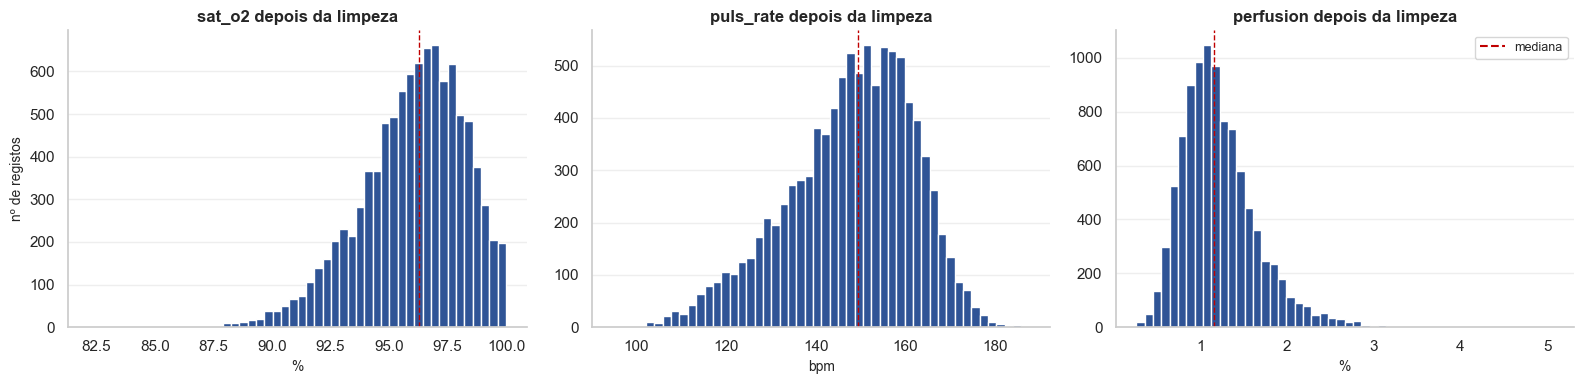

In [9]:
# =============================================================================
# 3.2.5 Correção dos valores dos sinais vitais
# Passo 5 – sinais vitais (2.4.6):
# - decimais com vírgula ('97,57') -> ponto ('97.57'); a coluna passa a numérica
# - valores fora do domínio (impossíveis) -> valor em falta (P4); só esse
#   valor é apagado, o registo mantém-se (os outros sinais estão corretos)
#     saturação ]0, 100] % | pulso [40, 300] bpm | perfusão ]0, 20] %
# - outliers plausíveis (IQR) e valores em falta originais mantêm-se.
#   Os valores em falta não são preenchidos aqui: a agregação diária (3.4)
#   calcula os resumos com as horas disponíveis.
# =============================================================================
DOMINIO = {"sat_o2": (0, 100), "puls_rate": (40, 300), "perfusion": (0, 20)}
EXCLUI_ZERO = {"sat_o2", "perfusion"}      # nestas variáveis um 0 significa "sem leitura"

linhas = []
for v in VITAIS:
    bruto = df_sinais[v]
    em_falta_orig = bruto.isna()
    texto = bruto.astype("string")
    com_virgula = texto.str.contains(",", regex=False).fillna(False)
    x = pd.to_numeric(texto.str.replace(",", ".", regex=False), errors="coerce").astype("float64")
    nao_convertidos = ~em_falta_orig & x.isna()                  # texto que não é número (deve ser 0)

    lo, hi = DOMINIO[v]
    abaixo = (x <= lo) if v in EXCLUI_ZERO else (x < lo)
    fora = abaixo | (x > hi)
    df_sinais[v] = x.mask(fora)

    linhas.append({"sinal vital": v, "vírgula -> ponto": com_virgula.sum(),
                   "não convertíveis": nao_convertidos.sum(), "fora do domínio -> em falta": fora.sum(),
                   "em falta (originais)": em_falta_orig.sum(), "em falta (total)": df_sinais[v].isna().sum(),
                   "% em falta": round(df_sinais[v].isna().mean() * 100, 2),
                   "mínimo": df_sinais[v].min(), "máximo": df_sinais[v].max()})
    registar("sinais vitais", "5. Sinais vitais", f"{v}: decimal com vírgula convertido", com_virgula.sum())
    registar("sinais vitais", "5. Sinais vitais", f"{v}: valor fora do domínio -> em falta", fora.sum())

display(pd.DataFrame(linhas).set_index("sinal vital"))
sem_nenhum = df_sinais[VITAIS].isna().all(axis=1)
print(f"Tipos das colunas: {df_sinais[VITAIS].dtypes.to_dict()}")
print(f"Registos sem nenhum sinal vital: {sem_nenhum.sum()} | "
      f"registos com algum valor em falta: {df_sinais[VITAIS].isna().any(axis=1).sum()}")

# --- Gráfico: distribuição de cada sinal vital depois da limpeza
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, VITAIS):
    ax.hist(df_sinais[v].dropna(), bins=50, color=AZUL)
    ax.axvline(df_sinais[v].median(), color=VERMELHO, ls="--", lw=1)
    ax.set_title(f"{v} depois da limpeza")
    ax.set_xlabel({"sat_o2": "%", "puls_rate": "bpm", "perfusion": "%"}[v])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("nº de registos")
axes[2].legend(handles=[Line2D([], [], color=VERMELHO, ls="--", label="mediana")], fontsize=9)
plt.tight_layout()
plt.show()

In [10]:
# =============================================================================
# 3.2.6 Correção dos nomes de patologia e linhas sem patologia
# Passo 6 – patologias (2.4.1 e 2.4.7):
# - variantes ('DMH', 'Sepsis', 'ANEMIA', 'icterícia'…) -> nome oficial, com
#   normalizar_patologia (3.1.2)
# - linhas sem patologia (12) -> removidas: 8 estão em dias que já têm outra
#   patologia (sobras); nas outras 4, pelo P3 um dia sem patologia registada
#   é tratado como "sem patologia", pelo que a linha vazia não acrescenta
#   informação (o dia continua a existir nos sinais vitais)
# - depois de agrupar os nomes, removem-se as linhas que passaram a ser
#   repetidas (ex.: 'DMH' e 'Doença das membranas hialinas' no mesmo dia;
#   na 2.4.7 não havia nenhuma)
# =============================================================================
original = df_patologias["patologia"].copy()
df_patologias["patologia"] = original.map(normalizar_patologia)
corrigidos = original.notna() & (original != df_patologias["patologia"])
sem_patologia = df_patologias["patologia"].isna()
nao_reconhecidos = original.notna() & sem_patologia            # deve ser 0

print(f"Nomes corrigidos: {corrigidos.sum()} | não reconhecidos: {nao_reconhecidos.sum()} | "
      f"linhas sem patologia: {(original.isna()).sum()}")
display(pd.DataFrame({"nome original": original[corrigidos].map(repr),
                      "nome oficial": df_patologias.loc[corrigidos, "patologia"]})
          .value_counts().rename("nº de registos").reset_index()
          .sort_values(["nome oficial", "nº de registos"], ascending=[True, False]).reset_index(drop=True))
registar("patologias", "6. Patologias", "Nome corrigido para o nome oficial", corrigidos.sum())

df_patologias.drop(index=df_patologias.index[sem_patologia], inplace=True)
registar("patologias", "6. Patologias", "Linha sem patologia removida", sem_patologia.sum())

repetidas = df_patologias.duplicated(keep="first")
df_patologias.drop(index=df_patologias.index[repetidas], inplace=True)
registar("patologias", "6. Patologias", "Linha repetida após agrupar os nomes removida", repetidas.sum())

print(f"Linhas repetidas após agrupar os nomes: {repetidas.sum()} | linhas: {len(original)} -> {len(df_patologias)}")
print(f"Todos os nomes são oficiais: {df_patologias['patologia'].isin(OFICIAIS).all()} | "
      f"patologias distintas: {df_patologias['patologia'].nunique()}")
display(df_patologias["patologia"].value_counts().rename("nº de registos").to_frame())

Nomes corrigidos: 45 | não reconhecidos: 0 | linhas sem patologia: 12


,nome original,nome oficial,nº de registos
0,'ANEMIA',Anemia,2
1,'Anemia ',Anemia,1
2,'anemia',Anemia,1
3,'CMV',Citomegalovírus,2
4,'Displasia Broncopulmonar',Displasia broncopulmonar,3
5,'Doenca das membranas hialinas',Doença das membranas hialinas,9
6,'doença das membranas hialinas ',Doença das membranas hialinas,7
7,'DMH',Doença das membranas hialinas,6
8,'Ictericia neonatal',Icterícia neonatal,5
9,'ICTERÍCIA NEONATAL',Icterícia neonatal,3


Linhas repetidas após agrupar os nomes: 0 | linhas: 679 -> 667
Todos os nomes são oficiais: True | patologias distintas: 10


,nº de registos
patologia,
Doença das membranas hialinas,282
Icterícia neonatal,161
Anemia,56
Citomegalovírus,49
Displasia broncopulmonar,38
Persistência do canal arterial,31
Refluxo gastroesofágico,27
Sépsis,18
Lesão renal aguda,3


In [11]:
# =============================================================================
# 3.2.7 Resumo da limpeza e verificação final
# 1) Tabela com todas as ações registadas nos passos 1 a 6 (registo_limpeza),
#    pronta para o Relatório de Limpeza dos Dados
# 2) Nº de linhas antes e depois da limpeza em cada tabela
# 3) Verificação final: cada regra de qualidade tem de ser cumprida pelas
#    tabelas limpas (True em todas as linhas)
# =============================================================================
# --- 1) Ações de limpeza
tab_limpeza = pd.DataFrame(registo_limpeza)
display(tab_limpeza)

# --- 2) Linhas antes e depois
antes_depois = pd.DataFrame({
    "linhas antes": [len(df_sinais_orig), len(df_patologias_orig)],
    "linhas depois": [len(df_sinais), len(df_patologias)]},
    index=["sinais vitais", "patologias"])
antes_depois["removidas"] = antes_depois["linhas antes"] - antes_depois["linhas depois"]
antes_depois["% removidas"] = (antes_depois["removidas"] / antes_depois["linhas antes"] * 100).round(2)
display(antes_depois)

# --- 3) Verificação final
s, p = df_sinais, df_patologias
regras = {
    "Sinais vitais – códigos no formato EPnnn": s["episodio"].str.fullmatch(r"EP\d{3}").all(),
    "Sinais vitais – datas válidas (tipo data, sem falhas)": pd.api.types.is_datetime64_any_dtype(s["data"]) and s["data"].notna().all(),
    "Sinais vitais – horas inteiras entre 0 e 23": pd.api.types.is_integer_dtype(s["hora"]) and s["hora"].between(0, 23).all(),
    "Sinais vitais – uma linha por episódio + data + hora": not s.duplicated(["episodio", "data", "hora"]).any(),
    "Sinais vitais – valores numéricos": all(pd.api.types.is_float_dtype(s[v]) for v in VITAIS),
    "Sinais vitais – valores dentro do domínio": all(
        ((s[v] > DOMINIO[v][0]) if v in EXCLUI_ZERO else (s[v] >= DOMINIO[v][0])).where(s[v].notna(), True).all()
        and (s[v] <= DOMINIO[v][1]).where(s[v].notna(), True).all() for v in VITAIS),
    "Patologias – códigos no formato EPnnn": p["episodio"].str.fullmatch(r"EP\d{3}").all(),
    "Patologias – datas válidas (tipo data, sem falhas)": pd.api.types.is_datetime64_any_dtype(p["data"]) and p["data"].notna().all(),
    "Patologias – nomes oficiais, sem linhas vazias": p["patologia"].isin(OFICIAIS).all(),
    "Patologias – sem linhas repetidas": not p.duplicated().any(),
}
display(pd.Series(regras, name="cumprida").to_frame())
print(f"Todas as regras cumpridas: {all(regras.values())}")
print(f"Episódios: sinais vitais {s['episodio'].nunique()} | patologias {p['episodio'].nunique()} | "
      f"período: {s['data'].min():%d/%m/%Y} a {s['data'].max():%d/%m/%Y}")

,tabela,passo,ação,registos afetados,linhas depois
0,sinais vitais,1. Códigos de episódio,Código corrigido (espaços/minúsculas),12,9857
1,patologias,1. Códigos de episódio,Código corrigido (espaços/minúsculas),6,696
2,sinais vitais,2. Datas,Data reescrita (DD/MM/AAAA -> AAAA-MM-DD),15,9854
3,sinais vitais,2. Datas,Registo removido (data impossível),3,9854
4,patologias,2. Datas,Data reescrita (DD/MM/AAAA -> AAAA-MM-DD),8,694
5,patologias,2. Datas,Registo removido (data impossível),2,694
6,sinais vitais,3. Horas,Hora atribuída (única hora em falta no dia),6,9852
7,sinais vitais,3. Horas,Registo removido (hora impossível de determinar),2,9852
8,sinais vitais,4. Duplicados,Linha totalmente repetida removida,60,9792
9,patologias,4. Duplicados,Linha totalmente repetida removida,15,679


,linhas antes,linhas depois,removidas,% removidas
sinais vitais,9857,9792,65,0.66
patologias,696,667,29,4.17


,cumprida
Sinais vitais – códigos no formato EPnnn,True
"Sinais vitais – datas válidas (tipo data, sem falhas)",True
Sinais vitais – horas inteiras entre 0 e 23,True
Sinais vitais – uma linha por episódio + data + hora,True
Sinais vitais – valores numéricos,True
Sinais vitais – valores dentro do domínio,True
Patologias – códigos no formato EPnnn,True
"Patologias – datas válidas (tipo data, sem falhas)",True
"Patologias – nomes oficiais, sem linhas vazias",True
Patologias – sem linhas repetidas,True


Todas as regras cumpridas: True
Episódios: sinais vitais 47 | patologias 39 | período: 30/01/2024 a 20/04/2024


### Relatório de Limpeza dos Dados (Data Cleaning Report)

A limpeza aplicou, pela ordem definida, as correções propostas no Relatório de Qualidade dos Dados (2.4). Todas as operações foram feitas em cópias de trabalho; as tabelas originais não foram alteradas.

**Ações realizadas**

| Passo | Problema (2.4) | Decisão e ação | Sinais vitais | Patologias |
|---|---|---|---|---|
| 1. Códigos de episódio | Códigos fora do formato EPnnn (minúsculas e espaços) | Código corrigido (retirar espaços e passar a maiúsculas) | 12 corrigidos | 6 corrigidos |
| 2. Datas | Datas no formato DD/MM/AAAA | Reescritas como AAAA-MM-DD | 15 reescritas | 8 reescritas |
| | Datas impossíveis (2024-13-02, 30 e 31 de fevereiro) | Registos removidos: não é possível saber a que dia pertencem | 3 removidos | 2 removidos |
| 3. Horas | Horas fora de 0–23 em dias com exatamente uma hora em falta | Atribuída a hora em falta: o registo pertence ao dia, não repete os valores de outra hora e a hora equivalente no dia ao lado já existe (2.4.5) | 6 corrigidos | — |
| | Horas fora de 0–23 em dias parciais | Registos removidos: não é possível determinar a hora | 2 removidos | — |
| 4. Duplicados | Linhas totalmente repetidas, sem contradições | Mantida a primeira ocorrência | 60 removidas | 15 removidas |
| 5. Sinais vitais | Decimais com vírgula | Vírgula substituída por ponto | 3 / 7 / 5 | — |
| | Valores fora do domínio (impossíveis) | Valor substituído por valor em falta; o registo mantém-se (P4) | 27 / 20 / 23 | — |
| 6. Patologias | Variantes de nomes (acentos, maiúsculas, espaços, abreviaturas, nomes incompletos) | Substituídas pelo nome oficial | — | 45 corrigidos |
| | Linhas sem patologia | Removidas: 8 estão em dias com outra patologia e as outras 4 não acrescentam informação, pois um dia sem patologia registada é tratado como "sem patologia" (P3) | — | 12 removidas |
| | Linhas repetidas após agrupar os nomes | Verificado: nenhuma | — | 0 |

*Nos sinais vitais, os três valores referem-se a saturação / pulso / perfusão.*

**Impacto nos dados**

| Tabela | Linhas antes | Linhas depois | Removidas |
|---|---|---|---|
| Sinais vitais | 9 857 | 9 792 | 65 (0,66 %) |
| Patologias | 696 | 667 | 29 (4,17 %) |

A maior parte das linhas removidas eram duplicados exatos (60 nos sinais vitais e 15 nas patologias), cuja remoção não implica perda de informação. Perderam-se apenas 5 medições horárias de sinais vitais por não ser possível determinar o seu dia ou hora, e 2 registos de patologia com data impossível. Os 47 episódios e o período dos dados (30/01/2024 a 20/04/2024) mantêm-se.

**Valores em falta nos sinais vitais**

Depois da limpeza ficam em falta 71 valores de saturação (0,73 %), 84 de pulso (0,86 %) e 65 de perfusão (0,66 %): os valores em falta originais mais os valores impossíveis convertidos. Estão em 219 registos (2,2 %), e nenhum registo ficou sem os três sinais vitais.

Os valores em falta **não foram preenchidos**. Como os sinais vitais vão ser resumidos por dia (3.4), cada resumo é calculado com as horas disponíveis: com 23 horas em vez de 24, a média, o mínimo e o máximo do dia quase não se alteram. Evita-se assim introduzir valores estimados, que poderiam enviesar os resultados.

**Outliers**

Os outliers pela regra do IQR (529 valores plausíveis, sobretudo na perfusão) foram mantidos, porque correspondem a medições possíveis e podem refletir o estado clínico dos bebés, que é precisamente o que os modelos devem aprender. As saturações de 100 % também se mantêm: são possíveis, por exemplo, em bebés com oxigénio suplementar.

**Verificação final**

Depois da limpeza, as tabelas cumprem todas as regras de qualidade verificadas:
- códigos no formato EPnnn;
- datas válidas;
- horas inteiras entre 0 e 23;
- uma única medição por episódio, data e hora;
- sinais vitais numéricos e dentro do domínio;
- nomes de patologia oficiais;
- ausência de linhas repetidas.

**Possível impacto nos resultados**

- A atribuição da hora em 6 registos assume que correspondem à única hora em falta do dia. Mesmo que a hora exata estivesse errada, o impacto é nulo nos resumos diários.
- A conversão de valores impossíveis em valores em falta assume que são códigos ou erros de registo (P4, a confirmar com o docente).
- A remoção das linhas sem patologia depende do pressuposto P3: se um dia sem patologia registada significar "sem registo" e não "sem patologia", esses dias terão de ser tratados de outra forma na construção das etiquetas (3.3).
- As patologias registadas em dias sem sinais vitais não foram removidas nesta fase: são excluídas do D1 na integração (3.4, pressuposto P2) e continuam a contar para o perfil dos episódios no D3.

## 3.3 Construção dos Dados (Construct Data)
> **CRISP-DM:** operações construtivas de preparação dos dados, como a produção de atributos derivados, de registos completamente novos ou de valores transformados de atributos existentes. Outputs: *Derived attributes* (atributos construídos a partir de um ou mais atributos do mesmo registo) e *Generated records* (registos novos, criados para representar explicitamente situações que não existem nos dados).

Nesta secção constroem-se:
- **indicadores clínicos por hora:** dessaturação, bradicardia, taquicardia e baixa perfusão, com limiares da literatura neonatal (3.3.1);
- **atributos do episódio:** dia do episódio, duração do internamento e dias que faltam até à alta, que é a variável alvo do D2 (3.3.2);
- **etiquetas das patologias:** uma coluna 0/1 por patologia em cada episódio-dia, que é a variável alvo do D1 (3.3.3);
- **registos gerados:** os episódio-dia com sinais vitais e sem patologia registada (3.3.4).

As agregações (de hora para dia e de dia para episódio) e as variáveis que dependem dos dias anteriores são construídas na integração (3.4).

,sinal vital,horas com o indicador,% das horas medidas,episódios com pelo menos 1 hora
dessaturacao,sat_o2,121,1.24,15
bradicardia,puls_rate,3,0.03,2
taquicardia,puls_rate,19,0.20,9
baixa_perfusao,perfusion,746,7.67,39


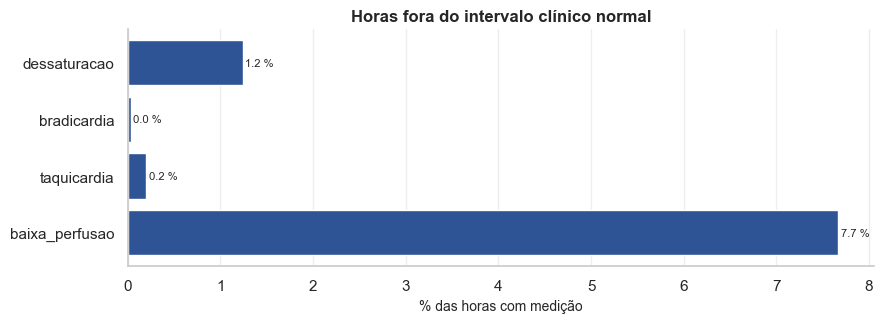

In [12]:
# =============================================================================
# 3.3.1 Indicadores clínicos por hora (atributos derivados)
# Para cada medição horária marca-se (1/0) se o valor está fora do intervalo
# clínico normal, com limiares da literatura neonatal (ver relatório da 2.4):
#   dessaturação   saturação < 90 %   (alvo dos prematuros: 90–95 %)
#   bradicardia    pulso < 100 bpm    (normal neonatal: 100–160 bpm, NICE)
#   taquicardia    pulso > 180 bpm    (anormal acima de 180 bpm, OMS)
#   baixa perfusão perfusão < 0,7 %   (abaixo do P5 dos recém-nascidos saudáveis)
# Foi também testado um indicador de hiperoxia (saturação > 95 %, acima do
# alvo dos prematuros), retirado por ocorrer em 70 % das horas: é o estado
# habitual destes bebés e não um evento, pelo que não distingue dias. O nível
# da saturação fica representado pelos resumos diários (3.4).
# Se o valor estiver em falta, o indicador também fica em falta (e não 0):
# não se sabe se nessa hora o valor estava normal ou não.
# Na 3.4 estes indicadores são somados por dia (nº de horas em cada situação).
# =============================================================================
INDICADORES = {
    "dessaturacao":   ("sat_o2",    lambda x: x < 90),
    "bradicardia":    ("puls_rate", lambda x: x < 100),
    "taquicardia":    ("puls_rate", lambda x: x > 180),
    "baixa_perfusao": ("perfusion", lambda x: x < 0.7),
}

for nome, (v, condicao) in INDICADORES.items():
    df_sinais[nome] = condicao(df_sinais[v]).astype(float).where(df_sinais[v].notna())

resumo_ind = pd.DataFrame({
    "sinal vital": [v for v, _ in INDICADORES.values()],
    "horas com o indicador": [int(df_sinais[n].sum()) for n in INDICADORES],
    "% das horas medidas": [round(df_sinais[n].mean() * 100, 2) for n in INDICADORES],
    "episódios com pelo menos 1 hora": [df_sinais.loc[df_sinais[n] == 1, "episodio"].nunique() for n in INDICADORES],
}, index=list(INDICADORES))
display(resumo_ind)

# --- Gráfico: % das horas medidas em cada situação
fig, ax = plt.subplots(figsize=(9, 3.4))
barras = ax.barh(resumo_ind.index, resumo_ind["% das horas medidas"], color=AZUL)
ax.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("% das horas com medição")
ax.set_title("Horas fora do intervalo clínico normal")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Episódio-dia: 449 | episódios: 47 | começam no limite: 3 | terminam no limite: 10
Exemplo – primeiros e últimos dias do EP001:


,episodio,data,dia_episodio,duracao,dias_ate_alta,comeca_no_limite,termina_no_limite
0,EP001,2024-01-30,1,24,23,True,False
1,EP001,2024-01-31,2,24,22,True,False
2,EP001,2024-02-01,3,24,21,True,False
22,EP001,2024-02-21,23,24,1,True,False
23,EP001,2024-02-22,24,24,0,True,False


,count,mean,std,min,25%,50%,75%,max
duracao (por episódio),47.0,9.55,8.17,1.0,3.5,7.0,13.5,36.0
"dias_ate_alta (D2, alta conhecida)",336.0,7.26,6.34,0.0,2.0,5.5,12.0,23.0


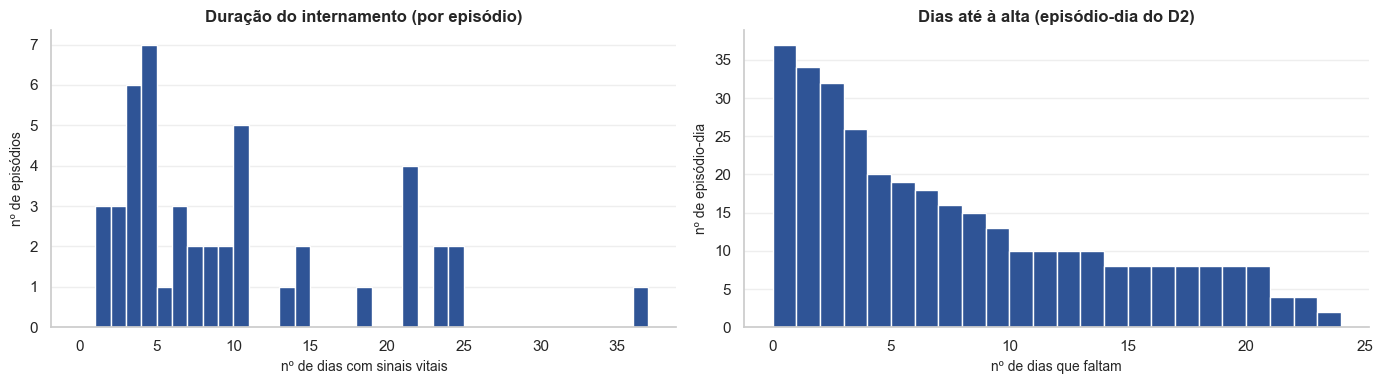

In [13]:
# =============================================================================
# 3.3.2 Atributos do episódio por episódio-dia
# Cria-se a tabela ep_dia, com uma linha por episódio-dia com sinais vitais
# (base do D1 e do D2), e os atributos:
#   dia_episodio      posição do dia no internamento (1, 2, 3, …), contando
#                     só os dias com sinais vitais (coerente com P1)
#   duracao           nº de dias com sinais vitais do episódio (P1)
#   dias_ate_alta     duracao - dia_episodio: nº de dias com sinais vitais
#                     que ainda faltam (0 no último dia) – alvo do D2 (P6)
#   comeca_no_limite  o episódio começa no 1.º dia dos dados (P5)
#   termina_no_limite o episódio termina no último dia dos dados (P5, P6)
# =============================================================================
ep_dia = (df_sinais[["episodio", "data"]].drop_duplicates()
          .sort_values(["episodio", "data"]).reset_index(drop=True))

por_ep = ep_dia.groupby("episodio")["data"]
ep_dia["dia_episodio"] = por_ep.cumcount() + 1
ep_dia["duracao"] = por_ep.transform("size")
ep_dia["dias_ate_alta"] = ep_dia["duracao"] - ep_dia["dia_episodio"]
ep_dia["comeca_no_limite"] = por_ep.transform("min") == df_sinais["data"].min()
ep_dia["termina_no_limite"] = por_ep.transform("max") == df_sinais["data"].max()

print(f"Episódio-dia: {len(ep_dia)} | episódios: {ep_dia['episodio'].nunique()} | "
      f"começam no limite: {ep_dia.loc[ep_dia['comeca_no_limite'], 'episodio'].nunique()} | "
      f"terminam no limite: {ep_dia.loc[ep_dia['termina_no_limite'], 'episodio'].nunique()}")
print("Exemplo – primeiros e últimos dias do EP001:")
display(pd.concat([ep_dia[ep_dia["episodio"] == "EP001"].head(3), ep_dia[ep_dia["episodio"] == "EP001"].tail(2)]))

duracoes = ep_dia.drop_duplicates("episodio").set_index("episodio")["duracao"]
alvo_d2 = ep_dia.loc[~ep_dia["termina_no_limite"], "dias_ate_alta"]
display(pd.DataFrame({"duracao (por episódio)": duracoes.describe(),
                      "dias_ate_alta (D2, alta conhecida)": alvo_d2.describe()}).round(2).T)

# --- Gráfico: duração dos episódios e dias até à alta
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(duracoes, bins=range(0, duracoes.max() + 2), color=AZUL)
axes[0].set_title("Duração do internamento (por episódio)")
axes[0].set_xlabel("nº de dias com sinais vitais")
axes[0].set_ylabel("nº de episódios")
axes[1].hist(alvo_d2, bins=range(0, alvo_d2.max() + 2), color=AZUL)
axes[1].set_title("Dias até à alta (episódio-dia do D2)")
axes[1].set_xlabel("nº de dias que faltam")
axes[1].set_ylabel("nº de episódio-dia")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [14]:
# =============================================================================
# 3.3.3 Etiquetas das patologias (multi-hot)
# Cada patologia passa a ser uma coluna 0/1 (variante multi-label do one-hot):
# 1 se a patologia foi registada nesse episódio-dia, 0 se não. Um dia pode
# ter várias colunas a 1 (várias patologias em simultâneo, H2).
# Só se criam colunas para as patologias de PATOLOGIAS_D1 (3.1.3): o reindex
# deixa de fora as excluídas (ex.: retinopatia) e garante sempre as mesmas
# colunas, pela mesma ordem.
# Nesta tabela estão todos os episódio-dia da tabela de patologias, com ou
# sem sinais vitais; a ligação aos dias com sinais vitais é feita na 3.3.4.
# =============================================================================
etiquetas = (pd.crosstab([df_patologias["episodio"], df_patologias["data"]], df_patologias["patologia"])
               .clip(upper=1)
               .reindex(columns=PATOLOGIAS_D1, fill_value=0)
               .astype(int))
etiquetas.columns.name = None

print(f"Episódio-dia na tabela de patologias: {len(etiquetas)} | colunas (patologias): {etiquetas.shape[1]}")
print(f"Valores diferentes de 0/1: {(~etiquetas.isin([0, 1])).sum().sum()}")
print(f"Episódio-dia sem nenhuma patologia de PATOLOGIAS_D1 (só patologias excluídas): "
      f"{(etiquetas.sum(axis=1) == 0).sum()}")
display(etiquetas.head())
display(etiquetas.sum().rename("nº de episódio-dia").to_frame().T)

Episódio-dia na tabela de patologias: 444 | colunas (patologias): 9
Valores diferentes de 0/1: 0
Episódio-dia sem nenhuma patologia de PATOLOGIAS_D1 (só patologias excluídas): 1


Doença das membranas hialinas  Icterícia neonatal  \
episodio data                                                            
EP001    2024-01-30                              0                   0   
         2024-01-31                              0                   0   
         2024-02-01                              0                   0   
         2024-02-02                              0                   0   
         2024-02-03                              0                   0   

                     Anemia  Citomegalovírus  Persistência do canal arterial  \
episodio data                                                                  
EP001    2024-01-30       0                0                               0   
         2024-01-31       0                0                               0   
         2024-02-01       0                0                               0   
         2024-02-02       0                0                               0   
         2024-02-03       0                0                               0   

                     Displasia broncopulmonar  Sépsis  \
episodio data                                           
EP001    2024-01-30                         1       0   
         2024-01-31                         1       0   
         2024-02-01                         1       0   
         2024-02-02                         1       0   
         2024-02-03                         1       0   

                     Refluxo gastroesofágico  Lesão renal aguda  
episodio data                                                    
EP001    2024-01-30                        1                  0  
         2024-01-31                        1                  0  
         2024-02-01                        1                  0  
         2024-02-02                        1                  0  
         2024-02-03                        1                  0

,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Persistência do canal arterial,Displasia broncopulmonar,Sépsis,Refluxo gastroesofágico,Lesão renal aguda
nº de episódio-dia,282,161,56,49,31,38,18,27,3


Episódio-dia com sinais vitais: 449
  com patologias registadas:            341
  gerados sem patologia (etiquetas a 0): 108 (em 36 episódios)
Episódio-dia com patologia mas sem sinais vitais (fora do D1, P2): 103

Nº de patologias por episódio-dia (D1):


nº de patologias,0,1,2,3,4
nº de episódio-dia,108,185,123,31,2


Episódio-dia com 2 ou mais patologias: 156 (45.7% dos dias com patologia)


,episódio-dia,% do D1,episódios,modelada
Doença das membranas hialinas,236,52.6,26,sim
Icterícia neonatal,117,26.1,20,sim
Anemia,43,9.6,6,sim
Citomegalovírus,32,7.1,6,sim
Persistência do canal arterial,30,6.7,3,sim
Displasia broncopulmonar,37,8.2,2,sim
Sépsis,12,2.7,2,sim
Refluxo gastroesofágico,23,5.1,1,não
Lesão renal aguda,2,0.4,1,não


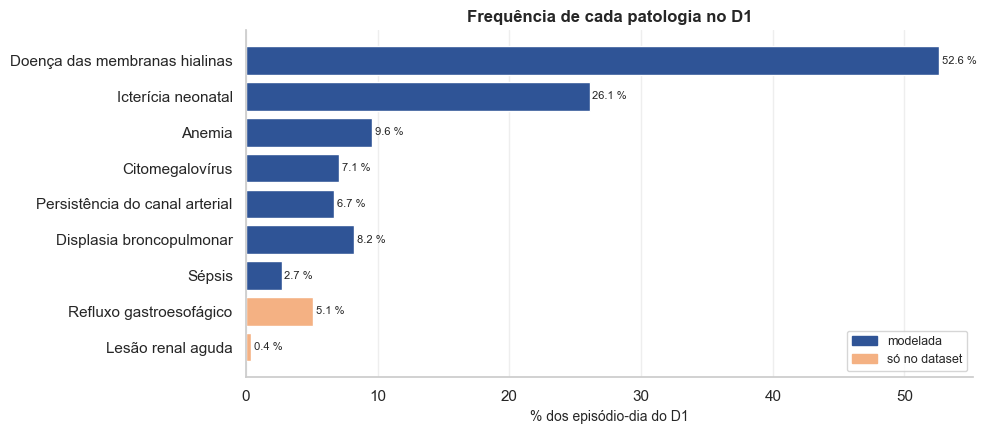

In [15]:
# =============================================================================
# 3.3.4 Registos gerados: episódio-dia sem patologia
# Junta as etiquetas (3.3.3) a todos os episódio-dia com sinais vitais
# (ep_dia, 3.3.2):
# - episódio-dia com sinais vitais e com patologias -> recebe as etiquetas
# - episódio-dia com sinais vitais e sem nenhuma patologia registada -> não
#   existe na tabela de patologias; gera-se um registo com todas as etiquetas
#   a 0 ("sem patologia", P3). Sem estes registos, o modelo nunca veria
#   exemplos de dias sem patologia.
# - episódio-dia com patologia mas sem sinais vitais -> não entram (P2);
#   são contados para o relatório
# Resultado: etiq_d1, com uma linha por episódio-dia com sinais vitais.
# =============================================================================
etiq_d1 = ep_dia[["episodio", "data"]].merge(etiquetas.reset_index(), on=["episodio", "data"],
                                             how="left", indicator=True)
gerados = etiq_d1["_merge"] == "left_only"
etiq_d1 = etiq_d1.drop(columns="_merge")
etiq_d1[PATOLOGIAS_D1] = etiq_d1[PATOLOGIAS_D1].fillna(0).astype(int)

chaves_sv = set(zip(ep_dia["episodio"], ep_dia["data"]))
sem_sv = [(e, d) not in chaves_sv for e, d in etiquetas.index]

print(f"Episódio-dia com sinais vitais: {len(etiq_d1)}")
print(f"  com patologias registadas:            {(~gerados).sum()}")
print(f"  gerados sem patologia (etiquetas a 0): {gerados.sum()} "
      f"(em {etiq_d1.loc[gerados, 'episodio'].nunique()} episódios)")
print(f"Episódio-dia com patologia mas sem sinais vitais (fora do D1, P2): {sum(sem_sv)}")

n_pat = etiq_d1[PATOLOGIAS_D1].sum(axis=1)
print("\nNº de patologias por episódio-dia (D1):")
display(n_pat.value_counts().sort_index().rename_axis("nº de patologias").to_frame("nº de episódio-dia").T)
print(f"Episódio-dia com 2 ou mais patologias: {(n_pat >= 2).sum()} "
      f"({(n_pat >= 2).sum() / (n_pat >= 1).sum():.1%} dos dias com patologia)")

prev = pd.DataFrame({"episódio-dia": etiq_d1[PATOLOGIAS_D1].sum(),
                     "% do D1": (etiq_d1[PATOLOGIAS_D1].mean() * 100).round(1),
                     "episódios": [etiq_d1.loc[etiq_d1[p] == 1, "episodio"].nunique() for p in PATOLOGIAS_D1],
                     "modelada": ["sim" if p in PATOLOGIAS_MODELO else "não" for p in PATOLOGIAS_D1]})
display(prev)

# --- Gráfico: % dos episódio-dia do D1 com cada patologia (desequilíbrio das classes)
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(prev.index, prev["% do D1"], color=prev["modelada"].map({"sim": AZUL, "não": LARANJA}))
ax.bar_label(barras, fmt="%.1f %%", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("% dos episódio-dia do D1")
ax.set_title("Frequência de cada patologia no D1")
ax.legend(handles=[Patch(color=AZUL, label="modelada"), Patch(color=LARANJA, label="só no dataset")],
          loc="lower right", fontsize=9)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Relatório de Construção dos Dados

**Atributos derivados**

| Atributo | Nível | Definição | Justificação |
|---|---|---|---|
| `dessaturacao` | Hora | 1 se saturação < 90 % | Abaixo do alvo de 90–95 % dos prematuros |
| `bradicardia` | Hora | 1 se pulso < 100 bpm | Abaixo do intervalo normal neonatal (100–160 bpm, NICE) |
| `taquicardia` | Hora | 1 se pulso > 180 bpm | Considerado anormal pela OMS |
| `baixa_perfusao` | Hora | 1 se perfusão < 0,7 % | Abaixo do P5 dos recém-nascidos saudáveis; pode indicar doença |
| `dia_episodio` | Episódio-dia | Posição do dia no internamento (1, 2, 3, …), contando só os dias com sinais vitais | Permite ao modelo saber em que fase do internamento está o bebé |
| `duracao` | Episódio | Nº de dias com sinais vitais (P1) | Duração do internamento, segundo a indicação do docente |
| `dias_ate_alta` | Episódio-dia | `duracao` − `dia_episodio` (0 no último dia) | **Variável alvo do D2** |
| `comeca_no_limite` | Episódio | O episódio começa no 1.º dia dos dados | Identifica episódios com início desconhecido (P5) |
| `termina_no_limite` | Episódio | O episódio termina no último dia dos dados | Identifica episódios com alta desconhecida (P5, P6) |
| 9 colunas de patologias | Episódio-dia | 1 se a patologia foi registada nesse dia, 0 se não (multi-hot) | **Variável alvo do D1**; um dia pode ter várias patologias |

Os indicadores horários usam limiares da literatura neonatal. Quando o sinal vital está em falta, o indicador fica também em falta, para não contar como "normal" uma hora sem medição. Foi também testado um indicador de hiperoxia (saturação > 95 %), retirado por ocorrer em 70 % das horas: é o estado habitual destes bebés e não um evento.

| Indicador | Horas | % das horas medidas | Episódios |
|---|---|---|---|
| Dessaturação | 121 | 1,24 % | 15 |
| Bradicardia | 3 | 0,03 % | 2 |
| Taquicardia | 19 | 0,20 % | 9 |
| Baixa perfusão | 746 | 7,67 % | 39 |

A duração do internamento tem mediana de 7 dias (entre 1 e 36). A variável alvo do D2, `dias_ate_alta`, tem mediana de 5,5 dias e máximo de 23 nos episódios com alta conhecida, com uma distribuição muito assimétrica: muitos dias perto da alta e poucos com mais de 15 dias pela frente.

**Registos gerados**

Os episódio-dia com sinais vitais e sem nenhuma patologia registada não existem na tabela de patologias. Foram gerados 108 registos (24 % do D1, em 36 episódios) com todas as etiquetas a 0, para representar explicitamente os dias "sem patologia" (P3). Sem estes registos, o modelo de classificação nunca veria exemplos de dias sem patologia.

**Etiquetas do D1**

| | Episódio-dia |
|---|---|
| Com sinais vitais (linhas do D1) | 449 |
| … com pelo menos uma patologia | 341 |
| … sem patologia (registos gerados) | 108 |
| Com patologia mas sem sinais vitais (fora do D1, P2) | 103 |

Dos 341 episódio-dia com patologia, 156 (45,7 %) têm duas ou mais patologias em simultâneo (185 com uma, 123 com duas, 31 com três e 2 com quatro), o que confirma que a classificação é um problema multi-label (H2).

| Patologia | Episódio-dia | % do D1 | Episódios | Modelada |
|---|---|---|---|---|
| Doença das membranas hialinas | 236 | 52,6 % | 26 | Sim |
| Icterícia neonatal | 117 | 26,1 % | 20 | Sim |
| Anemia | 43 | 9,6 % | 6 | Sim |
| Displasia broncopulmonar | 37 | 8,2 % | 2 | Sim |
| Citomegalovírus | 32 | 7,1 % | 6 | Sim |
| Persistência do canal arterial | 30 | 6,7 % | 3 | Sim |
| Sépsis | 12 | 2,7 % | 2 | Sim |
| Refluxo gastroesofágico | 23 | 5,1 % | 1 | Não |
| Lesão renal aguda | 2 | 0,4 % | 1 | Não |

As classes estão muito desequilibradas. Só a doença das membranas hialinas está presente em mais de metade dos dias; as restantes estão abaixo de 30 %, e a sépsis em apenas 2,7 %. Na modelação, a exatidão não é uma métrica adequada: um modelo que nunca previsse sépsis acertaria em 97 % dos dias. Por isso a avaliação usa o recall e o F1 por patologia (critérios de sucesso da Business Understanding), e devem ser consideradas técnicas para classes desequilibradas, como pesos por classe.

## 3.4 Integração dos Dados (Integrate Data)
> **CRISP-DM:** combinar informação de várias tabelas ou registos para criar novos registos ou valores. Inclui a junção de tabelas com informação diferente sobre os mesmos objetos (*merge*) e as agregações, em que novos valores são calculados a partir do resumo de vários registos. Output: *Merged data*.

Nesta secção:
- resumem-se as medições horárias dos sinais vitais por episódio-dia (3.4.1);
- constroem-se as variáveis que usam os dias anteriores do mesmo episódio (3.4.2);
- juntam-se os resumos diários, os atributos do episódio e as etiquetas das patologias nos três datasets: D1 (3.4.3), D2 (3.4.4) e D3 (3.4.5);
- analisa-se a relação entre os sinais vitais e as patologias, adiada da Fase 2 por exigir a integração das duas tabelas (3.4.6).

Linhas: 449 (episódio-dia) | colunas de resumo: 17
Mesmos episódio-dia que ep_dia: True
Dias com 24 horas: 351 | dias parciais: 98
Resumos em falta (dias sem nenhum valor de um sinal vital, ou desvio-padrão com 1 só hora):


'nenhum'

,mean,min,50%,max
sat_o2_media,95.99,91.28,96.24,99.88
sat_o2_min,93.17,82.19,93.56,98.70
sat_o2_max,98.20,92.91,98.46,100.00
sat_o2_dp,1.37,0.25,1.30,4.39
puls_rate_media,146.84,111.52,149.64,172.63
puls_rate_min,134.74,94.81,136.65,162.88
puls_rate_max,161.20,116.91,164.65,187.63
puls_rate_dp,7.17,1.69,6.73,17.84
perfusion_media,1.23,0.54,1.19,3.36
perfusion_min,0.77,0.26,0.75,3.24


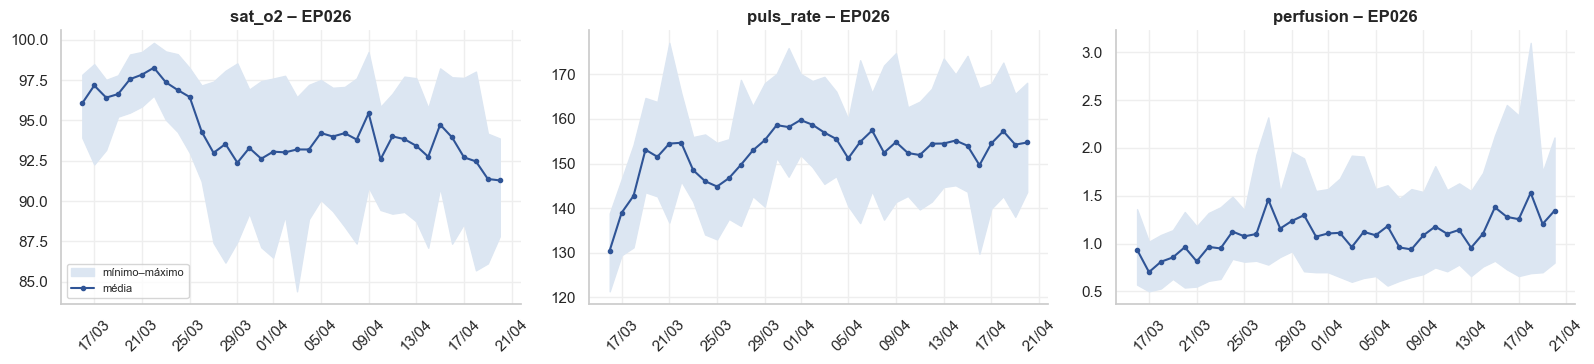

In [16]:
# =============================================================================
# 3.4.1 Agregação dos sinais vitais por episódio-dia
# As medições horárias são resumidas numa linha por episódio-dia (passa-se de
# ~24 linhas por dia para 1). Para cada sinal vital:
#   _media  nível típico do dia
#   _min    pior valor baixo do dia (ex.: queda de saturação)
#   _max    pior valor alto do dia (ex.: pico de pulso)
#   _dp     desvio-padrão: estabilidade (alto = bebé instável)
# E para o dia:
#   n_horas            nº de horas com registo (dias parciais têm menos)
#   pct_<indicador>    % das horas medidas em cada situação clínica (3.3.1);
#                      usa-se a % e não o nº de horas para comparar dias
#                      completos com dias parciais
# Os valores em falta são ignorados: cada resumo usa as horas disponíveis.
# =============================================================================
agregacoes = {}
for v in VITAIS:
    agregacoes.update({f"{v}_media": (v, "mean"), f"{v}_min": (v, "min"),
                       f"{v}_max": (v, "max"), f"{v}_dp": (v, "std")})
agregacoes["n_horas"] = ("hora", "size")
agregacoes.update({f"pct_{n}": (n, "mean") for n in INDICADORES})

diario = df_sinais.groupby(["episodio", "data"]).agg(**agregacoes).reset_index()
diario[[f"pct_{n}" for n in INDICADORES]] *= 100

print(f"Linhas: {len(diario)} (episódio-dia) | colunas de resumo: {diario.shape[1] - 2}")
print(f"Mesmos episódio-dia que ep_dia: {set(zip(diario['episodio'], diario['data'])) == chaves_sv}")
print(f"Dias com 24 horas: {(diario['n_horas'] == 24).sum()} | dias parciais: {(diario['n_horas'] < 24).sum()}")
falta = diario.drop(columns=["episodio", "data"]).isna().sum()
print("Resumos em falta (dias sem nenhum valor de um sinal vital, ou desvio-padrão com 1 só hora):")
display(falta[falta > 0].to_frame("nº de episódio-dia").T if (falta > 0).any() else "nenhum")
display(diario.drop(columns=["episodio", "data"]).describe().T.round(2)[["mean", "min", "50%", "max"]])

# --- Gráfico: exemplo de um episódio – média diária e intervalo mínimo–máximo
ex = diario[diario["episodio"] == diario.groupby("episodio").size().idxmax()]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, v in zip(axes, VITAIS):
    ax.fill_between(ex["data"], ex[f"{v}_min"], ex[f"{v}_max"], color=AZUL_CLARO, label="mínimo–máximo")
    ax.plot(ex["data"], ex[f"{v}_media"], color=AZUL, marker="o", ms=3, label="média")
    ax.set_title(f"{v} – {ex['episodio'].iloc[0]}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Variáveis criadas: ['sat_o2_var', 'sat_o2_desvio', 'puls_rate_var', 'puls_rate_desvio', 'perfusion_var', 'perfusion_desvio']
Em falta só no 1.º dia de cada episódio: True (47 episódio-dia)


,mean,std,min,50%,max
sat_o2_var,0.04,1.06,-3.20,0.03,3.36
sat_o2_desvio,0.05,1.31,-3.89,0.05,3.54
puls_rate_var,1.51,6.21,-23.28,1.09,26.38
puls_rate_desvio,5.77,7.69,-21.96,5.55,28.83
perfusion_var,0.02,0.28,-2.03,0.02,1.16
perfusion_desvio,0.09,0.29,-2.03,0.10,1.24


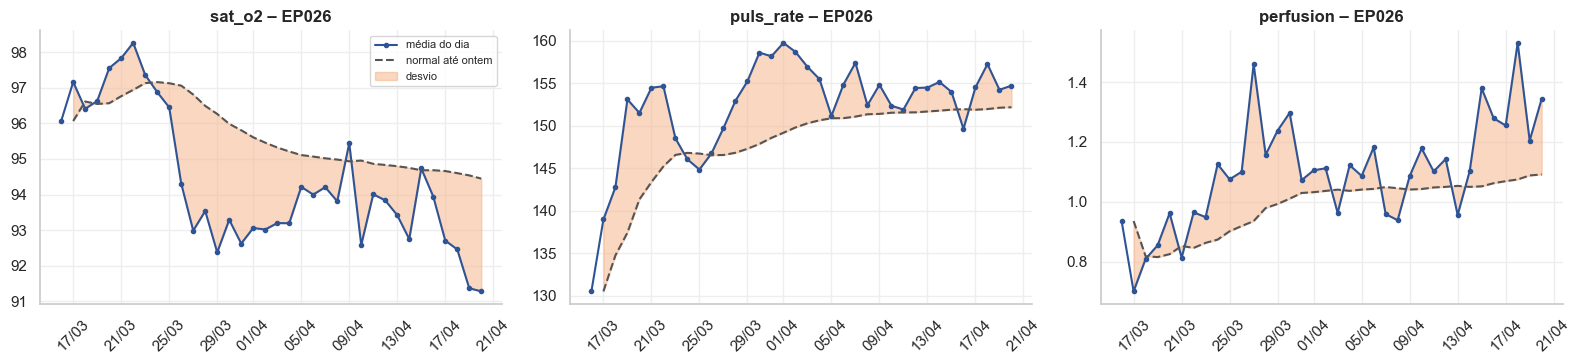

In [17]:
# =============================================================================
# 3.4.2 Variáveis dos dias anteriores (P8)
# Para cada episódio-dia, compara-se o dia atual com o passado do mesmo
# episódio (nunca com o futuro, para não haver fuga de informação):
#   <sinal>_var      variação da média em relação ao dia anterior com
#                    sinais vitais (hoje - ontem)
#   <sinal>_desvio   diferença entre a média de hoje e a média de todos os
#                    dias anteriores do episódio (o "normal" do próprio bebé
#                    até ontem, H8)
# No 1.º dia de cada episódio não há passado: estas variáveis ficam em falta
# (tratado na 3.5).
# =============================================================================
diario = diario.sort_values(["episodio", "data"]).reset_index(drop=True)
por_ep = diario.groupby("episodio")

for v in VITAIS:
    media = diario[f"{v}_media"]
    anterior = por_ep[f"{v}_media"].shift(1)                                   # dia anterior
    normal_ate_ontem = por_ep[f"{v}_media"].transform(lambda s: s.expanding().mean().shift(1))
    diario[f"{v}_var"] = media - anterior
    diario[f"{v}_desvio"] = media - normal_ate_ontem

novas = [f"{v}_{s}" for v in VITAIS for s in ["var", "desvio"]]
primeiro_dia = por_ep.cumcount() == 0
print(f"Variáveis criadas: {novas}")
print(f"Em falta só no 1.º dia de cada episódio: "
      f"{diario.loc[primeiro_dia, novas].isna().all().all() and diario.loc[~primeiro_dia, novas].notna().all().all()}"
      f" ({primeiro_dia.sum()} episódio-dia)")
display(diario[novas].describe().T.round(2)[["mean", "std", "min", "50%", "max"]])

# --- Gráfico: exemplo (mesmo episódio da 3.4.1) – média diária vs. "normal até ontem"
ex = diario[diario["episodio"] == ex["episodio"].iloc[0]]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, v in zip(axes, VITAIS):
    normal = ex[f"{v}_media"] - ex[f"{v}_desvio"]
    ax.plot(ex["data"], ex[f"{v}_media"], color=AZUL, marker="o", ms=3, label="média do dia")
    ax.plot(ex["data"], normal, color=CINZA, ls="--", label="normal até ontem")
    ax.fill_between(ex["data"], normal, ex[f"{v}_media"], color=LARANJA, alpha=0.5, label="desvio")
    ax.set_title(f"{v} – {ex['episodio'].iloc[0]}")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
# =============================================================================
# 3.4.3 Construção do D1 – Classificação das patologias
# Junta, para cada episódio-dia com sinais vitais:
#   resumos diários e variáveis dos dias anteriores (diario, 3.4.1–3.4.2)
#   + dia_episodio e comeca_no_limite (ep_dia, 3.3.2)
#   + etiquetas das patologias (etiq_d1, 3.3.3–3.3.4)
# Não entram no D1 a duração nem os dias até à alta: só se conhecem no fim do
# internamento, e dariam ao modelo informação do futuro (fuga de informação).
# validate="one_to_one" garante que cada episódio-dia aparece uma só vez em
# cada tabela (a junção não pode duplicar nem perder linhas).
# =============================================================================
CHAVE = ["episodio", "data"]
VARIAVEIS_DIA = [c for c in diario.columns if c not in CHAVE]
VARIAVEIS_EP = ["dia_episodio", "comeca_no_limite"]

d1 = (diario.merge(ep_dia[CHAVE + VARIAVEIS_EP], on=CHAVE, how="inner", validate="one_to_one")
            .merge(etiq_d1, on=CHAVE, how="inner", validate="one_to_one"))
d1 = d1[CHAVE + VARIAVEIS_DIA + VARIAVEIS_EP + PATOLOGIAS_D1]

print(f"D1: {d1.shape[0]} linhas × {d1.shape[1]} colunas "
      f"(2 de identificação + {len(VARIAVEIS_DIA) + len(VARIAVEIS_EP)} variáveis de entrada + "
      f"{len(PATOLOGIAS_D1)} etiquetas)")
print(f"Episódios: {d1['episodio'].nunique()} | linhas iguais às de ep_dia: {len(d1) == len(ep_dia)} | "
      f"episódio-dia repetidos: {d1.duplicated(CHAVE).sum()}")
print(f"Etiquetas iguais às da 3.3.4: {d1[PATOLOGIAS_D1].sum().equals(etiq_d1[PATOLOGIAS_D1].sum())}")

falta = d1.isna().sum()
print("\nValores em falta por coluna (tratados na 3.5):")
display(falta[falta > 0].to_frame("nº de episódio-dia").T)
display(d1.head(3))

D1: 449 linhas × 36 colunas (2 de identificação + 25 variáveis de entrada + 9 etiquetas)
Episódios: 47 | linhas iguais às de ep_dia: True | episódio-dia repetidos: 0
Etiquetas iguais às da 3.3.4: True

Valores em falta por coluna (tratados na 3.5):


,sat_o2_var,sat_o2_desvio,puls_rate_var,puls_rate_desvio,perfusion_var,perfusion_desvio
nº de episódio-dia,47,47,47,47,47,47


,episodio,data,sat_o2_media,sat_o2_min,sat_o2_max,sat_o2_dp,puls_rate_media,puls_rate_min,puls_rate_max,puls_rate_dp,perfusion_media,perfusion_min,perfusion_max,perfusion_dp,n_horas,pct_dessaturacao,pct_bradicardia,pct_taquicardia,pct_baixa_perfusao,sat_o2_var,sat_o2_desvio,puls_rate_var,puls_rate_desvio,perfusion_var,perfusion_desvio,dia_episodio,comeca_no_limite,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Persistência do canal arterial,Displasia broncopulmonar,Sépsis,Refluxo gastroesofágico,Lesão renal aguda
0,EP001,2024-01-30,92.949333,90.00,95.49,1.808122,156.748000,148.50,168.32,5.541287,1.083333,0.49,1.64,0.305933,15,0.0,0.0,0.0,6.666667,NaN,NaN,NaN,NaN,NaN,NaN,1,True,0,0,0,0,0,1,0,1,0
1,EP001,2024-01-31,94.213333,90.42,99.79,2.177074,160.556250,147.06,169.00,4.973546,0.962917,0.59,1.49,0.238555,24,0.0,0.0,0.0,16.666667,1.2640,1.2640,3.808250,3.808250,-0.120417,-0.120417,2,True,0,0,0,0,0,1,0,1,0
2,EP001,2024-02-01,94.175833,90.00,98.45,2.075222,161.395417,149.87,174.56,6.104747,1.149167,0.78,1.66,0.257123,24,0.0,0.0,0.0,0.000000,-0.0375,0.5945,0.839167,2.743292,0.186250,0.126042,3,True,0,0,0,0,0,1,0,1,0


In [19]:
# =============================================================================
# 3.4.4 Construção do D2 – Regressão dos dias até à alta
# Mesmas linhas do D1 (episódio-dia com sinais vitais), mas:
# - só episódios com alta conhecida (que não terminam no último dia dos
#   dados, P6); os outros são removidos porque a variável alvo é desconhecida
# - variáveis de entrada: as do D1 + as patologias do próprio dia (P8), que
#   aqui são informação conhecida nesse dia e não o que se quer prever
# - variável alvo: dias_ate_alta (3.3.2), na última coluna
# A duração do episódio não entra: só se conhece no fim (dias_ate_alta =
# duracao - dia_episodio, pelo que daria a resposta ao modelo).
# =============================================================================
ALVO_D2 = "dias_ate_alta"

d2 = d1.merge(ep_dia[CHAVE + ["termina_no_limite", ALVO_D2]], on=CHAVE, how="inner", validate="one_to_one")
removidas = d2["termina_no_limite"]
d2 = d2[~removidas].drop(columns="termina_no_limite").reset_index(drop=True)
d2 = d2[CHAVE + VARIAVEIS_DIA + VARIAVEIS_EP + PATOLOGIAS_D1 + [ALVO_D2]]

print(f"D2: {d2.shape[0]} linhas × {d2.shape[1]} colunas "
      f"(2 de identificação + {len(VARIAVEIS_DIA) + len(VARIAVEIS_EP) + len(PATOLOGIAS_D1)} variáveis de entrada "
      f"+ 1 variável alvo)")
print(f"Episódios: {d2['episodio'].nunique()} | linhas removidas (alta desconhecida): {removidas.sum()} "
      f"de {removidas.size} ({removidas.mean():.1%})")
print(f"Alvo em falta: {d2[ALVO_D2].isna().sum()} | linhas com alvo = 0 (dia da alta): {(d2[ALVO_D2] == 0).sum()} "
      f"(uma por episódio: {(d2[ALVO_D2] == 0).sum() == d2['episodio'].nunique()})")
display(d2[ALVO_D2].describe().round(2).to_frame().T)

# Média dos dias até à alta com e sem cada patologia (uma primeira ideia do seu efeito)
efeito = pd.DataFrame({
    "com a patologia": [d2.loc[d2[p] == 1, ALVO_D2].mean() for p in PATOLOGIAS_D1],
    "sem a patologia": [d2.loc[d2[p] == 0, ALVO_D2].mean() for p in PATOLOGIAS_D1],
    "episódio-dia com a patologia": [int(d2[p].sum()) for p in PATOLOGIAS_D1]}, index=PATOLOGIAS_D1).round(1)
print("Média dos dias até à alta nos episódio-dia com e sem cada patologia:")
display(efeito)

print("Primeiras linhas do D2:")
display(d2.head(3))

D2: 336 linhas × 37 colunas (2 de identificação + 34 variáveis de entrada + 1 variável alvo)
Episódios: 37 | linhas removidas (alta desconhecida): 113 de 449 (25.2%)
Alvo em falta: 0 | linhas com alvo = 0 (dia da alta): 37 (uma por episódio: True)


,count,mean,std,min,25%,50%,75%,max
dias_ate_alta,336.0,7.26,6.34,0.0,2.0,5.5,12.0,23.0


Média dos dias até à alta nos episódio-dia com e sem cada patologia:


,com a patologia,sem a patologia,episódio-dia com a patologia
Doença das membranas hialinas,7.7,6.8,170
Icterícia neonatal,8.0,7.0,87
Anemia,5.2,7.5,35
Citomegalovírus,8.6,7.1,32
Persistência do canal arterial,11.0,6.9,30
Displasia broncopulmonar,11.5,6.9,24
Sépsis,4.5,7.4,12
Refluxo gastroesofágico,11.9,6.9,23
Lesão renal aguda,19.5,7.2,2


Primeiras linhas do D2:


,episodio,data,sat_o2_media,sat_o2_min,sat_o2_max,sat_o2_dp,puls_rate_media,puls_rate_min,puls_rate_max,puls_rate_dp,perfusion_media,perfusion_min,perfusion_max,perfusion_dp,n_horas,pct_dessaturacao,pct_bradicardia,pct_taquicardia,pct_baixa_perfusao,sat_o2_var,sat_o2_desvio,puls_rate_var,puls_rate_desvio,perfusion_var,perfusion_desvio,dia_episodio,comeca_no_limite,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Persistência do canal arterial,Displasia broncopulmonar,Sépsis,Refluxo gastroesofágico,Lesão renal aguda,dias_ate_alta
0,EP001,2024-01-30,92.949333,90.00,95.49,1.808122,156.748000,148.50,168.32,5.541287,1.083333,0.49,1.64,0.305933,15,0.0,0.0,0.0,6.666667,NaN,NaN,NaN,NaN,NaN,NaN,1,True,0,0,0,0,0,1,0,1,0,23
1,EP001,2024-01-31,94.213333,90.42,99.79,2.177074,160.556250,147.06,169.00,4.973546,0.962917,0.59,1.49,0.238555,24,0.0,0.0,0.0,16.666667,1.2640,1.2640,3.808250,3.808250,-0.120417,-0.120417,2,True,0,0,0,0,0,1,0,1,0,22
2,EP001,2024-02-01,94.175833,90.00,98.45,2.075222,161.395417,149.87,174.56,6.104747,1.149167,0.78,1.66,0.257123,24,0.0,0.0,0.0,0.000000,-0.0375,0.5945,0.839167,2.743292,0.186250,0.126042,3,True,0,0,0,0,0,1,0,1,0,21


In [20]:
# =============================================================================
# 3.4.5 Construção do D3 – Clustering de episódios
# Uma linha por episódio, com o resumo de todo o internamento (agregação de
# hora/dia para episódio):
# - sinais vitais: média e desvio-padrão de todas as medições do episódio,
#   e % das horas em cada situação clínica (3.3.1)
# - duração (P1) e marcas de início/fim nos limites dos dados (P5)
# - perfil de patologias: 1 se o episódio teve a patologia em algum dia,
#   0 se não; aqui usam-se TODOS os registos de patologia, incluindo os dias
#   sem sinais vitais (só o D1 precisa de sinais vitais em cada dia), e todas
#   as patologias presentes nos dados (incluindo a retinopatia)
# - nº de patologias distintas do episódio
# No clustering não há variável alvo: o objetivo é descrever grupos de
# episódios semelhantes, depois do internamento.
# =============================================================================
agreg_ep = {}
for v in VITAIS:
    agreg_ep.update({f"{v}_media": (v, "mean"), f"{v}_dp": (v, "std")})
agreg_ep.update({f"pct_{n}": (n, "mean") for n in INDICADORES})
d3 = df_sinais.groupby("episodio").agg(**agreg_ep)
d3[[f"pct_{n}" for n in INDICADORES]] *= 100

info_ep = ep_dia.drop_duplicates("episodio").set_index("episodio")[["duracao", "comeca_no_limite", "termina_no_limite"]]
PATOLOGIAS_D3 = [p for p in OFICIAIS if p in set(df_patologias["patologia"])]
perfil = (pd.crosstab(df_patologias["episodio"], df_patologias["patologia"]).clip(upper=1)
            .reindex(index=d3.index, columns=PATOLOGIAS_D3, fill_value=0))
perfil.columns.name = None

d3 = d3.join(info_ep).join(perfil)
d3["n_patologias"] = d3[PATOLOGIAS_D3].sum(axis=1)
d3 = d3.reset_index()
VARIAVEIS_D3 = [c for c in d3.columns if c != "episodio"]

print(f"D3: {d3.shape[0]} linhas (episódios) × {d3.shape[1]} colunas (1 de identificação + {len(VARIAVEIS_D3)} variáveis)")
print(f"Patologias no perfil ({len(PATOLOGIAS_D3)}): {PATOLOGIAS_D3}")
print(f"Valores em falta: {d3.isna().sum().sum()} | episódios sem patologia: {(d3['n_patologias'] == 0).sum()}")
display(d3[PATOLOGIAS_D3].sum().rename("nº de episódios").to_frame().T)
display(d3["n_patologias"].value_counts().sort_index().rename_axis("nº de patologias").to_frame("nº de episódios").T)
display(d3.head(3))

D3: 47 linhas (episódios) × 25 colunas (1 de identificação + 24 variáveis)
Patologias no perfil (10): ['Doença das membranas hialinas', 'Icterícia neonatal', 'Anemia', 'Citomegalovírus', 'Displasia broncopulmonar', 'Persistência do canal arterial', 'Refluxo gastroesofágico', 'Sépsis', 'Lesão renal aguda', 'Retinopatia da prematuridade']
Valores em falta: 0 | episódios sem patologia: 8


,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Displasia broncopulmonar,Persistência do canal arterial,Refluxo gastroesofágico,Sépsis,Lesão renal aguda,Retinopatia da prematuridade
nº de episódios,28,21,7,7,2,3,2,3,1,2


nº de patologias,0,1,2,3,4,5
nº de episódios,8,17,13,5,2,2


,episodio,sat_o2_media,sat_o2_dp,puls_rate_media,puls_rate_dp,perfusion_media,perfusion_dp,pct_dessaturacao,pct_bradicardia,pct_taquicardia,pct_baixa_perfusao,duracao,comeca_no_limite,termina_no_limite,Doença das membranas hialinas,Icterícia neonatal,Anemia,Citomegalovírus,Displasia broncopulmonar,Persistência do canal arterial,Refluxo gastroesofágico,Sépsis,Lesão renal aguda,Retinopatia da prematuridade,n_patologias
0,EP001,93.920522,1.986090,158.698180,6.579512,1.173219,0.330716,3.956835,0.0,0.000000,4.316547,24,True,False,0,0,1,0,1,0,1,0,0,1,4
1,EP002,94.945179,1.929943,141.907321,6.203588,1.358421,0.324553,0.000000,0.0,0.000000,0.000000,3,True,False,0,0,0,1,0,0,0,0,0,0,1
2,EP003,97.553701,1.228771,162.586984,8.308776,1.176299,0.504481,0.000000,0.0,0.793651,11.811024,6,True,False,1,1,0,0,0,0,0,0,0,0,2


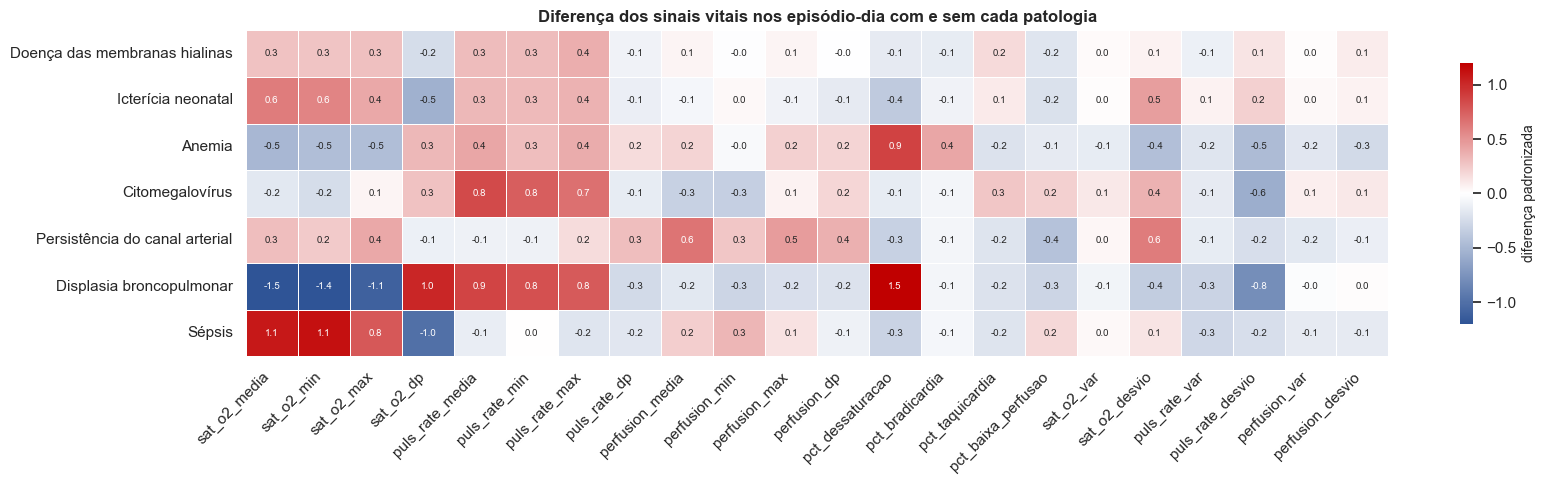

As 3 variáveis com maior diferença para cada patologia:


,episódio-dia com a patologia,1.ª,2.ª,3.ª
Doença das membranas hialinas,236,puls_rate_max (+0.38),puls_rate_media (+0.31),puls_rate_min (+0.31)
Icterícia neonatal,117,sat_o2_media (+0.61),sat_o2_min (+0.58),sat_o2_dp (-0.55)
Anemia,43,pct_dessaturacao (+0.89),sat_o2_media (-0.50),puls_rate_desvio (-0.47)
Citomegalovírus,32,puls_rate_media (+0.85),puls_rate_min (+0.75),puls_rate_max (+0.67)
Persistência do canal arterial,30,perfusion_media (+0.65),sat_o2_desvio (+0.61),perfusion_max (+0.46)
Displasia broncopulmonar,37,pct_dessaturacao (+1.51),sat_o2_media (-1.46),sat_o2_min (-1.36)
Sépsis,12,sat_o2_min (+1.12),sat_o2_media (+1.09),sat_o2_dp (-1.00)


In [21]:
# =============================================================================
# 3.4.6 Relação entre os sinais vitais e as patologias
# Análise adiada da Fase 2 (exigia a integração das duas tabelas). Usa o D1.
# Para cada patologia modelada e cada variável diária dos sinais vitais,
# compara os episódio-dia COM e SEM a patologia através da diferença
# padronizada:
#     (média com a patologia - média sem a patologia) / desvio-padrão da variável
# Lê-se em "nº de desvios-padrão": 0 = sem diferença; ±0,2 pequena;
# ±0,5 média; ±0,8 ou mais grande. Positivo (vermelho) = valores mais altos
# nos dias com a patologia; negativo (azul) = mais baixos.
# Análise descritiva: os dias do mesmo bebé não são independentes e as
# diferenças podem refletir bebés diferentes (H8), e não só a patologia.
# =============================================================================
from matplotlib.colors import LinearSegmentedColormap

VARS_ANALISE = [c for c in VARIAVEIS_DIA if c != "n_horas"]
dif = pd.DataFrame(index=PATOLOGIAS_MODELO, columns=VARS_ANALISE, dtype=float)
for p in PATOLOGIAS_MODELO:
    com, sem = d1[d1[p] == 1], d1[d1[p] == 0]
    for c in VARS_ANALISE:
        dif.loc[p, c] = (com[c].mean() - sem[c].mean()) / d1[c].std()

cmap = LinearSegmentedColormap.from_list("azul_vermelho", [AZUL, "white", VERMELHO])
fig, ax = plt.subplots(figsize=(17, 5))
sns.heatmap(dif, cmap=cmap, center=0, vmin=-1.2, vmax=1.2, annot=True, fmt=".1f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="white", cbar_kws={"label": "diferença padronizada", "shrink": 0.8}, ax=ax)
ax.grid(False)
ax.set_title("Diferença dos sinais vitais nos episódio-dia com e sem cada patologia")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Variáveis com maior diferença (em valor absoluto) para cada patologia
top = pd.DataFrame({p: [f"{c} ({dif.loc[p, c]:+.2f})" for c in dif.loc[p].abs().sort_values(ascending=False).index[:3]]
                    for p in PATOLOGIAS_MODELO}, index=["1.ª", "2.ª", "3.ª"]).T
top.insert(0, "episódio-dia com a patologia", [int(d1[p].sum()) for p in PATOLOGIAS_MODELO])
print("As 3 variáveis com maior diferença para cada patologia:")
display(top)

### Relatório de Integração dos Dados (Merged Data)

**Agregação dos sinais vitais por episódio-dia (3.4.1)**

As 9 792 medições horárias foram resumidas em 449 episódio-dia. Para cada sinal vital calcularam-se a média (nível do dia), o mínimo e o máximo (piores momentos) e o desvio-padrão (estabilidade). Para o dia, calcularam-se o nº de horas com registo e a % das horas medidas em cada situação clínica (3.3.1). Usa-se a percentagem, e não o nº de horas, para comparar dias completos com dias parciais (média de 21,8 horas por dia, mínimo de 2). A mediana não foi incluída por ser praticamente igual à média num dia de 24 medições. Os valores em falta foram ignorados: cada resumo usa as horas disponíveis.

**Variáveis dos dias anteriores (3.4.2)**

Para cada sinal vital, criaram-se duas variáveis que comparam o dia atual com o passado do mesmo episódio, sem nunca usar dias futuros (P8):
- `_var`: variação da média em relação ao dia anterior com sinais vitais;
- `_desvio`: diferença entre a média do dia e a média de todos os dias anteriores do episódio, ou seja, o "normal" do próprio bebé até à véspera (H8).

No 1.º dia de cada episódio não há passado, pelo que estas variáveis ficam em falta em 47 episódio-dia (tratado na 3.5).

**Datasets resultantes**

| Dataset | Linhas | Episódios | Variáveis de entrada | Variável alvo |
|---|---|---|---|---|
| D1 – Classificação | 449 episódio-dia | 47 | 25: resumos diários (17), dias anteriores (6), `dia_episodio`, `comeca_no_limite` | 9 colunas 0/1 de patologias (7 modeladas) |
| D2 – Regressão | 336 episódio-dia | 37 | 34: as do D1 + as 9 patologias do próprio dia | `dias_ate_alta` |
| D3 – Clustering | 47 episódios | 47 | 24: sinais vitais do internamento (10), `duracao`, marcas de limite (2), perfil de 10 patologias, `n_patologias` | — |

- **D1:** junção dos resumos diários, dos atributos do episódio e das etiquetas. Não inclui a duração nem os dias até à alta, que só se conhecem no fim do internamento (fuga de informação).
- **D2:** as mesmas linhas, sem os 10 episódios que terminam no último dia dos dados (113 episódio-dia, 25 %), cuja alta é desconhecida (P6). As patologias do próprio dia entram como variáveis de entrada, porque são conhecidas nesse dia e não são o que se pretende prever (P8). A duração não entra, porque com o dia do episódio daria diretamente a resposta.
- **D3:** uma linha por episódio. O perfil de patologias usa todos os registos de patologia, incluindo os dos 103 dias sem sinais vitais, e todas as patologias presentes nos dados (incluindo a retinopatia). A duração pode entrar, porque o clustering descreve os internamentos depois de terminados.

Todas as junções foram validadas como um-para-um (cada episódio-dia aparece uma única vez em cada tabela), sem perda nem duplicação de linhas.

**Relação entre os sinais vitais e as patologias (3.4.6)**

Compararam-se os episódio-dia com e sem cada patologia através da diferença padronizada (diferença das médias a dividir pelo desvio-padrão da variável):

| Patologia | Episódio-dia | Diferenças mais relevantes | Interpretação |
|---|---|---|---|
| Displasia broncopulmonar | 37 (2 episódios) | Mais horas em dessaturação (+1,5), saturação mais baixa (−1,5) e mais instável (+1,0), pulso mais alto (+0,9) | Coerente com doença pulmonar crónica; parte da diferença reflete os 2 bebés |
| Anemia | 43 | Mais dessaturação (+0,9), saturação mais baixa (−0,5), pulso mais alto (+0,4) | Coerente com menor transporte de oxigénio e compensação cardíaca |
| Persistência do canal arterial | 30 | Perfusão mais alta (+0,65) e acima do normal do bebé na saturação (+0,6) | Coerente com o aumento do fluxo periférico |
| Citomegalovírus | 32 | Pulso mais alto (+0,85), mas abaixo do normal do próprio bebé (−0,6) | A diferença é do bebé e não do dia (H8) |
| Icterícia neonatal | 117 | Saturação mais alta (+0,6) e mais estável (−0,5) | Pode refletir bebés mais estáveis |
| Sépsis | 12 (2 episódios) | Saturação mais alta (+1,1) e mais estável (−1,0) | Contrário ao esperado; provável efeito dos 2 bebés |
| Doença das membranas hialinas | 236 | Apenas diferenças pequenas (pulso +0,3) | A patologia mais frequente é a mais difícil de distinguir pelos sinais vitais |

Existem diferenças médias a grandes nos sinais vitais para várias patologias, algumas com explicação clínica, o que indica que os modelos de classificação têm informação para aprender. No entanto, as diferenças mais fortes surgem nas patologias com menos episódios, onde podem refletir os bebés e não as patologias; a separação de treino e teste por episódio é, por isso, essencial na Fase 4.

As variáveis de variação diária (`_var`) não mostram diferenças para nenhuma patologia, ao contrário das variáveis de desvio em relação ao normal do bebé (`_desvio`). São candidatas a ser retiradas na seleção de variáveis. Esta análise é descritiva: os episódio-dia do mesmo bebé não são independentes.

## 3.5 Formatação dos Dados (Format Data)
> **CRISP-DM:** transformações de formato, sobretudo sintáticas, que não alteram o significado dos dados mas podem ser exigidas pela ferramenta de modelação: ordem dos atributos (ex.: identificador primeiro e variável alvo no fim), ordem dos registos e alterações de sintaxe. Output: *Reformatted data*. No fim da fase: *Dataset* e *Dataset Description*.

Nesta secção:
- tratam-se os valores em falta que restam (3.5.1);
- verifica-se a redundância entre as variáveis de entrada (3.5.2);
- uniformizam-se os tipos de dados e a ordem das colunas e das linhas (3.5.3);
- gravam-se os três datasets e a respetiva descrição (3.5.4).

A normalização das escalas (*scaling*) não é aplicada nesta fase. Os parâmetros (por exemplo, a mediana e o IQR do *robust scaling*) têm de ser calculados apenas com os dados de treino, para não haver fuga de informação, pelo que o *scaling* é feito na Fase 4, dentro do processo de treino.

In [22]:
# =============================================================================
# 3.5.1 Valores em falta nos datasets
# Os únicos valores em falta são as variáveis dos dias anteriores (_var e
# _desvio) no 1.º dia de cada episódio, que não tem passado (3.4.2).
# Decisão: preencher com 0 ("sem diferença em relação ao passado"), um valor
# por defeito (insertion of suitable defaults, CRISP-DM). Não se perde
# informação, porque o modelo sabe que é o 1.º dia pela variável
# dia_episodio = 1. Alternativas como apagar estas linhas (perder 47 dias,
# incluindo o dia de entrada) ou estimar valores a partir de outros dias
# (usar dias futuros = fuga de informação) foram rejeitadas.
# Por segurança, um desvio-padrão em falta num dia com 1 só hora (sem
# variação possível) também passa a 0 (nos dados atuais não há nenhum).
# Verifica-se no fim que nenhum dataset tem valores em falta.
# =============================================================================
VARS_PASSADO = [f"{v}_{s}" for v in VITAIS for s in ["var", "desvio"]]

for nome, df in [("D1", d1), ("D2", d2)]:
    em_falta = df[VARS_PASSADO].isna()
    so_no_1o_dia = (em_falta.any(axis=1) == (df["dia_episodio"] == 1)).all()
    df[VARS_PASSADO] = df[VARS_PASSADO].fillna(0)
    dp_cols = [f"{v}_dp" for v in VITAIS]
    df.loc[df["n_horas"] == 1, dp_cols] = df.loc[df["n_horas"] == 1, dp_cols].fillna(0)
    print(f"{nome}: {em_falta.any(axis=1).sum()} linhas preenchidas com 0 "
          f"(todas no 1.º dia do episódio: {so_no_1o_dia})")

for nome, df in [("D1", d1), ("D2", d2), ("D3", d3)]:
    print(f"{nome}: valores em falta depois do tratamento = {df.isna().sum().sum()}")

D1: 47 linhas preenchidas com 0 (todas no 1.º dia do episódio: True)
D2: 37 linhas preenchidas com 0 (todas no 1.º dia do episódio: True)
D1: valores em falta depois do tratamento = 0
D2: valores em falta depois do tratamento = 0
D3: valores em falta depois do tratamento = 0


D1/D2 – pares com |correlação| > 0.9: 2


,variável A,variável B,correlação
0,puls_rate_media,puls_rate_min,0.954448
1,sat_o2_media,sat_o2_min,0.901417


D3 – pares com |correlação| > 0.9: 0


,variável A,variável B,correlação


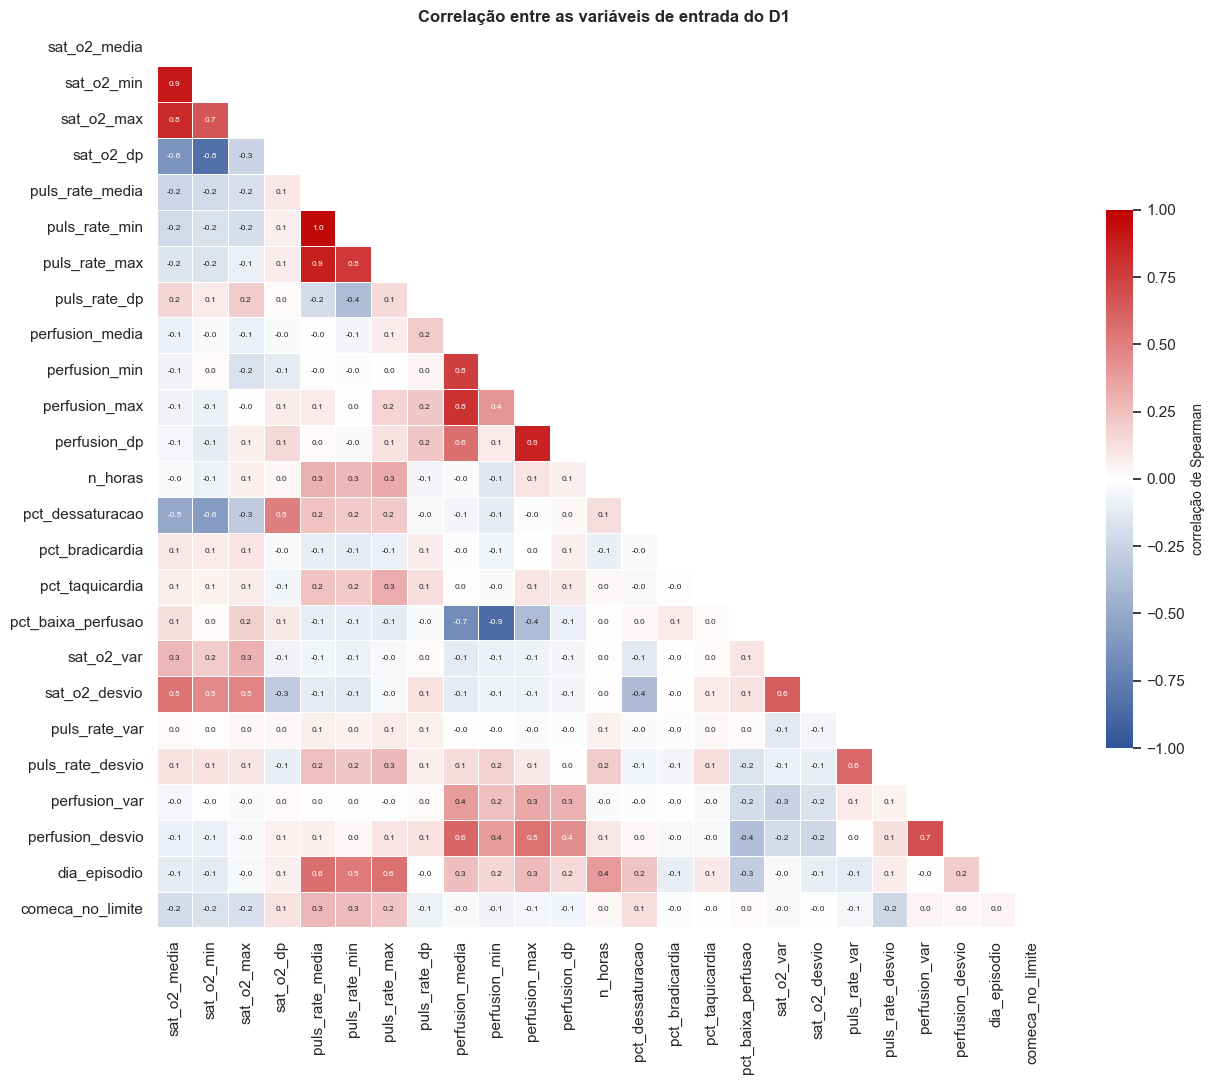

In [23]:
# =============================================================================
# 3.5.2 Redundância entre as variáveis de entrada
# Duas variáveis muito correlacionadas (|r| > LIMIAR_CORR) dão praticamente a
# mesma informação: manter as duas aumenta o nº de variáveis sem acrescentar
# informação (risco de overfitting, ver guia de feature engineering – filter
# methods).
# Calcula-se a correlação de Spearman entre as variáveis de entrada numéricas
# do D1 (as mesmas do D2, sem as patologias) e do D3, e listam-se os pares
# acima do limiar. A decisão de retirar variáveis é tomada com base nesta
# lista. Não usa a variável alvo, pelo que não há fuga de informação.
# =============================================================================
LIMIAR_CORR = 0.9

def pares_correlacionados(df, colunas, limiar=LIMIAR_CORR):
    corr = df[colunas].astype(float).corr(method="spearman")
    pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(colunas) for b in colunas[i + 1:]
             if abs(corr.loc[a, b]) > limiar]
    return corr, pd.DataFrame(pares, columns=["variável A", "variável B", "correlação"]).sort_values(
        "correlação", key=abs, ascending=False).reset_index(drop=True)

entradas_d1 = VARIAVEIS_DIA + VARIAVEIS_EP
entradas_d3 = [c for c in VARIAVEIS_D3 if c not in PATOLOGIAS_D3]

corr_d1, pares_d1 = pares_correlacionados(d1, entradas_d1)
corr_d3, pares_d3 = pares_correlacionados(d3, entradas_d3)
print(f"D1/D2 – pares com |correlação| > {LIMIAR_CORR}: {len(pares_d1)}")
display(pares_d1)
print(f"D3 – pares com |correlação| > {LIMIAR_CORR}: {len(pares_d3)}")
display(pares_d3)

# --- Gráfico: matriz de correlação das variáveis de entrada do D1 (triângulo inferior)
cmap = LinearSegmentedColormap.from_list("azul_vermelho", [AZUL, "white", VERMELHO])
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr_d1, mask=np.triu(np.ones_like(corr_d1, dtype=bool)), cmap=cmap, center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 6}, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "correlação de Spearman", "shrink": 0.6}, ax=ax)
ax.grid(False)
ax.set_title("Correlação entre as variáveis de entrada do D1")
plt.tight_layout()
plt.show()

In [24]:
# =============================================================================
# 3.5.3 Variáveis retiradas, tipos de dados e ordem das colunas e linhas
# 1) Retiram-se as variáveis redundantes identificadas na 3.5.2
#    (|correlação| > 0,9 com a média do mesmo sinal vital): fica a média
# 2) Tipos de dados uniformes para as ferramentas de modelação:
#    - verdadeiro/falso (comeca_no_limite, termina_no_limite) -> 0/1 (int)
#    - etiquetas e perfil de patologias, contagens e alvo do D2 -> int
#    - restantes variáveis de entrada -> float
# 3) Ordem das colunas: identificação primeiro, variável alvo no fim
#    Ordem das linhas: por episódio e data (ordem cronológica)
# =============================================================================
VARS_REMOVIDAS = ["puls_rate_min", "sat_o2_min"]

d1 = d1.drop(columns=VARS_REMOVIDAS)
d2 = d2.drop(columns=VARS_REMOVIDAS)
ENTRADAS_D1 = [c for c in VARIAVEIS_DIA + VARIAVEIS_EP if c not in VARS_REMOVIDAS]
ENTRADAS_D2 = ENTRADAS_D1 + PATOLOGIAS_D1
ENTRADAS_D3 = VARIAVEIS_D3

INTEIRAS = ["n_horas", "dia_episodio", "comeca_no_limite", "termina_no_limite", "duracao",
            "n_patologias", ALVO_D2] + PATOLOGIAS_D3
for df in (d1, d2, d3):
    for c in df.columns:
        if c in ("episodio", "data"):
            continue
        df[c] = df[c].astype(int) if c in INTEIRAS else df[c].astype(float)

d1 = d1[CHAVE + ENTRADAS_D1 + PATOLOGIAS_D1].sort_values(CHAVE).reset_index(drop=True)
d2 = d2[CHAVE + ENTRADAS_D2 + [ALVO_D2]].sort_values(CHAVE).reset_index(drop=True)
d3 = d3[["episodio"] + ENTRADAS_D3].sort_values("episodio").reset_index(drop=True)

resumo_fmt = pd.DataFrame({
    "linhas": [len(d1), len(d2), len(d3)],
    "identificação": [len(CHAVE), len(CHAVE), 1],
    "variáveis de entrada": [len(ENTRADAS_D1), len(ENTRADAS_D2), len(ENTRADAS_D3)],
    "variável alvo": [f"{len(PATOLOGIAS_D1)} patologias (0/1)", ALVO_D2, "—"],
    "tipos": [", ".join(f"{t}: {n}" for t, n in df.dtypes.astype(str).value_counts().items()) for df in (d1, d2, d3)],
}, index=["D1 – Classificação", "D2 – Regressão", "D3 – Clustering"])
display(resumo_fmt)
print(f"Variáveis retiradas por redundância: {VARS_REMOVIDAS}")
print(f"Valores em falta: D1 {d1.isna().sum().sum()} | D2 {d2.isna().sum().sum()} | D3 {d3.isna().sum().sum()}")

,linhas,identificação,variáveis de entrada,variável alvo,tipos
D1 – Classificação,449,2,23,9 patologias (0/1),"float64: 20, int64: 12, str: 1, datetime64[us]: 1"
D2 – Regressão,336,2,32,dias_ate_alta,"float64: 20, int64: 13, str: 1, datetime64[us]: 1"
D3 – Clustering,47,1,24,—,"int64: 14, float64: 10, str: 1"


Variáveis retiradas por redundância: ['puls_rate_min', 'sat_o2_min']
Valores em falta: D1 0 | D2 0 | D3 0


In [25]:
# =============================================================================
# 3.5.4 Gravação dos datasets e do dicionário de dados
# Grava os três datasets finais em CSV na pasta dados_preparados/ (os
# ficheiros originais da pasta dados/ não são alterados):
#   d1_classificacao.csv | d2_regressao.csv | d3_clustering.csv
# e um dicionário de dados (dicionario_datasets.csv) com, para cada coluna de
# cada dataset: o papel (identificação, entrada ou alvo), o tipo e a descrição.
# No fim, os ficheiros são lidos de novo para confirmar que foram bem gravados.
# Estes ficheiros são o ponto de partida da Fase 4 (Modelação).
# =============================================================================
PASTA_SAIDA = "dados_preparados/"
os.makedirs(PASTA_SAIDA, exist_ok=True)
FICHEIROS = {"D1": ("d1_classificacao.csv", d1), "D2": ("d2_regressao.csv", d2), "D3": ("d3_clustering.csv", d3)}

# --- Descrição de cada coluna
NOME_SINAL = {"sat_o2": ("da saturação de oxigénio", "%"), "puls_rate": ("do pulso", "bpm"), "perfusion": ("da perfusão", "%")}
RESUMO = {"media": "média", "min": "mínimo", "max": "máximo", "dp": "desvio-padrão"}
SITUACAO = {"dessaturacao": "saturação < 90 %", "bradicardia": "pulso < 100 bpm",
            "taquicardia": "pulso > 180 bpm", "baixa_perfusao": "perfusão < 0,7 %"}

def descrever(col, dataset):
    if col == "episodio":
        return "Código do episódio (EPnnn)"
    if col == "data":
        return "Data do episódio-dia (AAAA-MM-DD)"
    for v, (nome, unid) in NOME_SINAL.items():
        if col.startswith(v + "_"):
            s = col[len(v) + 1:]
            periodo = "do internamento" if dataset == "D3" else "do dia"
            if s in RESUMO:
                return f"{RESUMO[s].capitalize()} {nome} {periodo} ({unid})"
            if s == "var":
                return f"Variação da média diária {nome} em relação ao dia anterior ({unid}); 0 no 1.º dia"
            if s == "desvio":
                return f"Diferença entre a média diária {nome} e a média dos dias anteriores do episódio ({unid}); 0 no 1.º dia"
    if col.startswith("pct_"):
        periodo = "do internamento" if dataset == "D3" else "do dia"
        return f"% das horas medidas {periodo} com {SITUACAO[col[4:]]}"
    if col in OFICIAIS:
        if dataset == "D3":
            return "1 se o episódio teve a patologia em algum dia do internamento, 0 se não"
        return "1 se a patologia foi registada nesse dia, 0 se não"
    outras = {"n_horas": "Nº de horas com registo de sinais vitais no dia",
              "dia_episodio": "Posição do dia no internamento (1 = 1.º dia com sinais vitais)",
              "comeca_no_limite": "1 se o episódio começa no 1.º dia dos dados (início pode ser anterior)",
              "termina_no_limite": "1 se o episódio termina no último dia dos dados (alta desconhecida)",
              "duracao": "Nº de dias com sinais vitais do episódio (duração do internamento)",
              "n_patologias": "Nº de patologias distintas registadas no episódio",
              ALVO_D2: "Nº de dias com sinais vitais que faltam até à alta (0 no último dia)"}
    return outras[col]

def papel(col, dataset):
    if col in ("episodio", "data"):
        return "identificação"
    if (dataset == "D1" and col in PATOLOGIAS_D1) or (dataset == "D2" and col == ALVO_D2):
        return "alvo"
    return "entrada"

dicionario = pd.DataFrame([{"dataset": ds, "coluna": c, "papel": papel(c, ds), "tipo": str(df[c].dtype),
                            "descrição": descrever(c, ds)}
                           for ds, (_, df) in FICHEIROS.items() for c in df.columns])

# --- Gravação e verificação
for ds, (fich, df) in FICHEIROS.items():
    df.to_csv(os.path.join(PASTA_SAIDA, fich), index=False, date_format="%Y-%m-%d")
dicionario.to_csv(os.path.join(PASTA_SAIDA, "dicionario_datasets.csv"), index=False)

for ds, (fich, df) in FICHEIROS.items():
    lido = pd.read_csv(os.path.join(PASTA_SAIDA, fich))
    print(f"{ds}: {fich} gravado | {lido.shape[0]} linhas × {lido.shape[1]} colunas | "
          f"igual ao dataset: {lido.shape == df.shape and list(lido.columns) == list(df.columns)}")
print(f"Dicionário: dicionario_datasets.csv ({len(dicionario)} colunas descritas)\n")
display(dicionario)

D1: d1_classificacao.csv gravado | 449 linhas × 34 colunas | igual ao dataset: True
D2: d2_regressao.csv gravado | 336 linhas × 35 colunas | igual ao dataset: True
D3: d3_clustering.csv gravado | 47 linhas × 25 colunas | igual ao dataset: True
Dicionário: dicionario_datasets.csv (94 colunas descritas)



,dataset,coluna,papel,tipo,descrição
0,D1,episodio,identificação,str,Código do episódio (EPnnn)
1,D1,data,identificação,datetime64[us],Data do episódio-dia (AAAA-MM-DD)
2,D1,sat_o2_media,entrada,float64,Média da saturação de oxigénio do dia (%)
3,D1,sat_o2_max,entrada,float64,Máximo da saturação de oxigénio do dia (%)
4,D1,sat_o2_dp,entrada,float64,Desvio-padrão da saturação de oxigénio do dia (%)
...,...,...,...,...,...
89,D3,Refluxo gastroesofágico,entrada,int64,"1 se o episódio teve a patologia em algum dia do internamento, 0 se não"
90,D3,Sépsis,entrada,int64,"1 se o episódio teve a patologia em algum dia do internamento, 0 se não"
91,D3,Lesão renal aguda,entrada,int64,"1 se o episódio teve a patologia em algum dia do internamento, 0 se não"
92,D3,Retinopatia da prematuridade,entrada,int64,"1 se o episódio teve a patologia em algum dia do internamento, 0 se não"


### Relatório de Formatação dos Dados (Reformatted Data)

**Valores em falta (3.5.1)**

Os únicos valores em falta eram as variáveis dos dias anteriores (`_var` e `_desvio`) no 1.º dia de cada episódio, que não tem passado (47 linhas no D1 e 37 no D2). Foram preenchidos com 0, ou seja, "sem diferença em relação ao passado", um valor por defeito que não introduz informação falsa: o modelo sabe que se trata do 1.º dia pela variável `dia_episodio`.

As alternativas foram rejeitadas:
- **apagar as linhas** eliminaria o 1.º dia de cada episódio, precisamente o da previsão à entrada;
- **estimar os valores a partir de outros dias** exigiria usar dias futuros (fuga de informação).

Depois deste tratamento, nenhum dos três datasets tem valores em falta.

**Variáveis redundantes (3.5.2)**

Calculou-se a correlação de Spearman entre as variáveis de entrada, sem usar a variável alvo. Consideraram-se redundantes os pares com correlação superior a 0,9 em valor absoluto, um limiar habitual para este critério:

| Par | Correlação | Decisão |
|---|---|---|
| `puls_rate_media` – `puls_rate_min` | 0,95 | Retirado `puls_rate_min` |
| `sat_o2_media` – `sat_o2_min` | 0,90 | Retirado `sat_o2_min` |

Manteve-se a média, por ser mais estável (resume todas as horas do dia, enquanto o mínimo depende de um único momento). A informação do "pior momento" continua representada pela % de horas em dessaturação e em bradicardia. A remoção não é igual para todos os sinais vitais: na saturação e no pulso o mínimo acompanha a média, enquanto na perfusão, cuja distribuição é assimétrica, o mínimo mantém informação própria (correlação de 0,8 com a média). No D3 nenhum par ultrapassou o limiar.

As variáveis de variação diária (`_var`) não são redundantes com outras, mas não mostraram diferenças entre dias com e sem patologia (3.4.6). Ficam para a seleção de variáveis da Fase 4, com base no desempenho dos modelos.

**Tipos e ordem (3.5.3)**

- Variáveis verdadeiro/falso convertidas em 0/1.
- Etiquetas, contagens e variável alvo do D2 como números inteiros.
- Restantes variáveis de entrada como números decimais.
- Colunas ordenadas com a identificação primeiro e a variável alvo no fim.
- Linhas ordenadas por episódio e data.

**Normalização das escalas (scaling)**

As variáveis estão em escalas muito diferentes (por exemplo, pulso entre 110 e 175 bpm e perfusão entre 0,5 % e 3,4 %). Optou-se pelo *robust scaling* (subtrair a mediana e dividir pelo IQR), por ser pouco sensível aos outliers plausíveis que foram mantidos na limpeza. **Não foi aplicado nesta fase.** A mediana e o IQR têm de ser calculados apenas com os dados de treino, pelo que o *scaling* será aplicado na Fase 4, dentro do processo de treino. Os modelos baseados em árvores não necessitam de *scaling*.

**Ficheiros gravados (3.5.4)**

| Ficheiro | Conteúdo |
|---|---|
| `dados_preparados/d1_classificacao.csv` | D1 – 449 linhas × 34 colunas |
| `dados_preparados/d2_regressao.csv` | D2 – 336 linhas × 35 colunas |
| `dados_preparados/d3_clustering.csv` | D3 – 47 linhas × 25 colunas |
| `dados_preparados/dicionario_datasets.csv` | Papel (identificação, entrada ou alvo), tipo e descrição de cada coluna dos três datasets |

Os ficheiros originais da pasta `dados/` não foram alterados.

## Descrição dos Datasets (Dataset Description)

A Fase 3 produziu três datasets, um por objetivo de data mining, construídos a partir dos dados limpos (3.2) e sem valores em falta. A descrição completa de cada coluna está em `dados_preparados/dicionario_datasets.csv`.

| | D1 – Classificação | D2 – Regressão | D3 – Clustering |
|---|---|---|---|
| **Objetivo** | DM1: detetar as patologias de cada dia | DM2: prever os dias que faltam até à alta | DM3: agrupar episódios por perfil clínico |
| **Ficheiro** | `d1_classificacao.csv` | `d2_regressao.csv` | `d3_clustering.csv` |
| **Unidade (1 linha =)** | Episódio-dia com sinais vitais | Episódio-dia com sinais vitais, de episódios com alta conhecida | Episódio |
| **Linhas** | 449 | 336 | 47 |
| **Episódios** | 47 | 37 | 47 |
| **Identificação** | `episodio`, `data` | `episodio`, `data` | `episodio` |
| **Variáveis de entrada** | 23 | 32 | 24 |
| **Variável alvo** | 9 colunas 0/1 de patologias (7 a modelar) | `dias_ate_alta` | — |

**Variáveis de entrada**

| Grupo | D1 | D2 | D3 |
|---|---|---|---|
| Resumos dos sinais vitais | Do dia: média, máximo e desvio-padrão da saturação e do pulso; média, mínimo, máximo e desvio-padrão da perfusão | Iguais ao D1 | Do internamento: média e desvio-padrão de cada sinal vital |
| Situações clínicas | % das horas do dia em dessaturação, bradicardia, taquicardia e baixa perfusão | Iguais ao D1 | % das horas do internamento nas mesmas situações |
| Dias anteriores | Variação em relação ao dia anterior e diferença em relação ao normal do bebé, para cada sinal vital | Iguais ao D1 | — |
| Episódio | `n_horas`, `dia_episodio`, `comeca_no_limite` | Iguais ao D1 | `duracao`, `comeca_no_limite`, `termina_no_limite` |
| Patologias | — (são o alvo) | 9 patologias registadas no próprio dia | Perfil de 10 patologias (teve ou não no internamento) e `n_patologias` |

**Características a ter em conta na modelação**

- **Dependência entre linhas:** no D1 e no D2, os dias do mesmo episódio são muito semelhantes. A separação entre treino e teste, incluindo a validação cruzada, tem de ser feita **por episódio**, para não sobrestimar o desempenho.
- **Classes desequilibradas (D1):** só a doença das membranas hialinas está presente em mais de metade dos dias (52,6 %); a sépsis está em 2,7 %. A avaliação deve usar o recall e o F1 por patologia e considerar técnicas para classes desequilibradas.
- **Poucos episódios em algumas patologias (D1):** a displasia broncopulmonar e a sépsis aparecem em apenas 2 episódios cada; os seus resultados terão pouca robustez.
- **Multi-label (D1):** 45,7 % dos dias com patologia têm duas ou mais em simultâneo; treina-se um classificador binário por patologia.
- **Distribuição assimétrica do alvo (D2):** muitos dias perto da alta e poucos com mais de 15 dias pela frente (mediana de 5,5, máximo de 23). Deve testar-se uma transformação logarítmica.
- **Censura à direita (D2):** os 10 episódios com alta desconhecida foram excluídos, sobretudo internamentos longos; o modelo poderá subestimar as durações mais longas.
- **Episódios com início desconhecido:** nos 3 episódios que começam no 1.º dia dos dados, o `dia_episodio` está subestimado; a variável `comeca_no_limite` identifica-os, e estes episódios não devem entrar na avaliação da previsão à entrada.
- **Ausência de fuga de informação:** no D1 e no D2, todas as variáveis de entrada usam apenas o próprio dia e os anteriores (P8); a duração do internamento não entra em nenhum dos dois.
- **Escalas diferentes:** aplicar *robust scaling* na Fase 4, ajustado apenas aos dados de treino, nos modelos que dele necessitem.

**Pressupostos a confirmar com o docente**

Os datasets dependem dos pressupostos P1 a P8 definidos no início da fase. Se as respostas do docente os alterarem, sobretudo o P1 (duração = dias com sinais vitais), o P3 (dia sem patologia registada = sem patologia) e o P6 (previsão diária dos dias até à alta), basta ajustar a construção correspondente (3.3 ou 3.4) e voltar a correr o notebook.